In [1]:
import joblib
import sys
import os
sys.path.append(os.path.abspath(".."))
from model.model import read_scale_data
from evaluation.flux_energy import physical_values
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

I0000 00:00:1789552136.963884 2551437 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789552137.007913 2551437 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789552139.835016 2551437 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
#### insert data set
metrics_dir = '/work/bb1097/b383521/ML_models/coarsed_grained/metrics/'
metrics_data = joblib.load(metrics_dir + 'results_cnn_coarsed_grained.pkl')
regimes      = joblib.load(metrics_dir + 'regimes_cnn_coarsed_grained.pkl')
tag = ["land", "ocean"]
season_tag = ['jan', 'aug', 'combined']
metrics = ['mse_train', 'mse_val', 'mse_test', 'R2_train', 'R2_val', 'R2_test', 'mae_train', 'mae_val', 'mae_test', 'mae_train_norm_std', 
           'mae_val_norm_std', 'mae_test_norm_std', 'skill_train', 'skill_val', 'skill_test', 'n_train', 'n_val', 'n_test']

In [3]:
import numpy as np
import pandas as pd

rows = []
index = []

for t in tag:
    for s in season_tag:
        row = {}
        for m in metrics:
            try:
                val = metrics_data[t][s][m]
                row[m] = np.nanmean(val)   # collapse the 144 values into their mean
            except KeyError:
                row[m] = np.nan
        rows.append(row)
        index.append((t, s))

df = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=["tag", "season"]))

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(df.round(4))

                mse_train  mse_val  mse_test  R2_train  R2_val  R2_test   mae_train     mae_val    mae_test  mae_train_norm_std  mae_val_norm_std  mae_test_norm_std  skill_train  skill_val  \
tag   season                                                                                                                                                                                   
land  jan          0.4529   0.8408    1.2815    0.9050  0.8331   0.7461  11617.2728  18648.6541  20224.5919              0.1175            0.2016             0.2262       0.6188     0.4804   
      aug          0.4914   0.9341    1.3631    0.8864  0.7903   0.7017   8703.8448  10372.8548  11697.5620              0.1672            0.2003             0.2227       0.5948     0.5184   
      combined     0.4723   0.8874    1.3223    0.8985  0.8176   0.7309  10153.8458  14510.7545  15961.0770              0.1301            0.1898             0.2116       0.6098     0.5003   
ocean jan          0.4349   0.8404    1.

In [ ]:
_, _, y_train_land, _, _, _, _, ntri_land  = read_scale_data(
																																model_save_dir="/work/bb1097/b383521/ML_models/coarsed_grained/",
                                coarse_action_dir_jan="/work/bb1097/b383521/GW_Data/coarsed_action/", land_ocean_tag="land")

_, _, y_train_ocean, _, _, _, _, ntri_ocean  = read_scale_data(
																																model_save_dir="/work/bb1097/b383521/ML_models/coarsed_grained/",
                                coarse_action_dir_jan="/work/bb1097/b383521/GW_Data/coarsed_action/",
																																land_ocean_tag="ocean")

Loading databases...
Combined shapes → X_train: (8622, 217, 111), y_train: (8622, 217, 6, 6, 4)
Combined shapes → X_test:  (8622, 44, 111), y_test:  (8622, 44, 6, 6, 4)
Combined shapes → X_val:   (8622, 30, 111), y_val:   (8622, 30, 6, 6, 4)


ValueError: too many values to unpack (expected 8)

In [5]:
with  xr.open_dataset(f"/work/bb1097/b383521/GW_Data/coarsed_action/coarse_gw_spectrum_group_{1}_fileslide_0.nc") as ds:
      k  = ds.k.data
      l  = ds.l.data
      m  = ds.m.data
# after re-running/restoring the original k, l, m wavenumber arrays:
k_wavenumber_array = k    # or whatever the correct array is, copy it to a safer name
l_wavenumber_array = l

In [6]:
import numpy as np

N_train_land = np.expm1(y_train_land)
N_train_ocean = np.expm1(y_train_ocean)
N_ing_train_land = np.sum(N_train_land, axis=1)
N_ing_train_ocean = np.sum(N_train_ocean, axis=1)

idx_max_ocean = np.argmax(N_ing_train_ocean)
idx_max_land = np.argmax(N_ing_train_land)

max_y_train_land = y_train_land[idx_max_land, :].reshape(6, 6, 4)
max_y_train_ocean = y_train_ocean[idx_max_ocean, :].reshape(6, 6, 4)

max_integrated_land = np.sum(np.expm1(max_y_train_land))
max_integrated_ocean = np.sum(np.expm1(max_y_train_ocean))

mean_y_train_land = np.nanmean(y_train_land, axis=0).reshape(6, 6, 4)
mean_y_train_ocean = np.nanmean(y_train_ocean, axis=0).reshape(6, 6, 4)
std_y_train_land = np.nanstd(y_train_land, axis=0).reshape(6, 6, 4)
std_y_train_ocean = np.nanstd(y_train_ocean, axis=0).reshape(6, 6, 4)

mean_integrated_land = np.sum(np.expm1(mean_y_train_land))
mean_integrated_ocean = np.sum(np.expm1(mean_y_train_ocean))

cv_y_train_land = std_y_train_land / mean_y_train_land
cv_y_train_ocean = std_y_train_ocean / mean_y_train_ocean

# --- Key numbers for text ---
print("=" * 60)
print("STATS TO CONFIRM/CITE IN TEXT (OCEAN ONLY)")
print("=" * 60)

print(f"\n1. Max event integrated energy (ocean): {max_integrated_ocean:.4e}")
print(f"   Max event integrated energy (land):  {max_integrated_land:.4e}")
land_vs_ocean_max_pct = (max_integrated_land / max_integrated_ocean - 1) * 100
print(f"   Land vs Ocean (max event): {land_vs_ocean_max_pct:+.1f}%")

print(f"\n2. Mean spectrum integrated energy (ocean): {mean_integrated_ocean:.4e}")
print(f"   Mean spectrum integrated energy (land):  {mean_integrated_land:.4e}")
land_vs_ocean_mean_pct = (mean_integrated_land / mean_integrated_ocean - 1) * 100
print(f"   Land vs Ocean (mean spectrum): {land_vs_ocean_mean_pct:+.1f}%")

print(f"\n3. Ratio: max event / typical (mean) event, OCEAN:")
print(f"   {max_integrated_ocean / mean_integrated_ocean:.1f}x")
print(f"   Ratio: max event / typical (mean) event, LAND:")
print(f"   {max_integrated_land / mean_integrated_land:.1f}x")

# --- Locate peak bin in mean/std for ocean (center vs edge comparison) ---
print(f"\n4. OCEAN mean spectrum: max value and location")
flat_idx = np.unravel_index(np.argmax(mean_y_train_ocean), mean_y_train_ocean.shape)
print(f"   Peak mean bin at (k_idx,l_idx,m_idx)={flat_idx}, value={mean_y_train_ocean[flat_idx]:.3f}")

print(f"\n5. OCEAN std spectrum: max value and location")
flat_idx_std = np.unravel_index(np.argmax(std_y_train_ocean), std_y_train_ocean.shape)
print(f"   Peak std bin at (k_idx,l_idx,m_idx)={flat_idx_std}, value={std_y_train_ocean[flat_idx_std]:.3f}")

print(f"\n6. OCEAN: mean value AT the peak-std bin location (checking low-mean/high-var claim):")
print(f"   mean={mean_y_train_ocean[flat_idx_std]:.3f}, std={std_y_train_ocean[flat_idx_std]:.3f}, "
      f"CV={cv_y_train_ocean[flat_idx_std]:.3f}")

print(f"\n7. OCEAN: std value AT the peak-mean (center) bin location (checking high-mean/low-var claim):")
print(f"   mean={mean_y_train_ocean[flat_idx]:.3f}, std={std_y_train_ocean[flat_idx]:.3f}, "
      f"CV={cv_y_train_ocean[flat_idx]:.3f}")

for j, lam in enumerate(m):
    print(f"\nlambda_z index={j} (lam={lam}): OCEAN mean spectrum, center 2x2 block:\n"
          f"{mean_y_train_ocean[2:4, 2:4, j]}")
    # "How concentrated is the peak" - e.g., fraction of total energy in the single max bin vs. spread out
ocean_lz12 = max_y_train_ocean[:, :, 0]  # log-space, lambda_z=12km slice
print("Ocean lz=12km: max value =", ocean_lz12.max(), " mean value =", ocean_lz12.mean(), 
      " std =", ocean_lz12.std())
print("Max bin as fraction of total (log-space sum):", ocean_lz12.max() / ocean_lz12.sum())

# Compare activity level across lambda_z for this specific event (not the mean spectrum)
for j, lam in enumerate(m):
    slice_j = max_y_train_ocean[:, :, j]
    print(f"lambda_z index {j}: mean={slice_j.mean():.3f}, max={slice_j.max():.3f}, std={slice_j.std():.3f}")

STATS TO CONFIRM/CITE IN TEXT (OCEAN ONLY)

1. Max event integrated energy (ocean): 4.0081e+07
   Max event integrated energy (land):  5.8093e+08
   Land vs Ocean (max event): +1349.4%

2. Mean spectrum integrated energy (ocean): 3.8911e+05
   Mean spectrum integrated energy (land):  4.5220e+05
   Land vs Ocean (mean spectrum): +16.2%

3. Ratio: max event / typical (mean) event, OCEAN:
   103.0x
   Ratio: max event / typical (mean) event, LAND:
   1284.7x

4. OCEAN mean spectrum: max value and location
   Peak mean bin at (k_idx,l_idx,m_idx)=(2, 3, 0), value=10.010

5. OCEAN std spectrum: max value and location
   Peak std bin at (k_idx,l_idx,m_idx)=(5, 1, 0), value=3.673

6. OCEAN: mean value AT the peak-std bin location (checking low-mean/high-var claim):
   mean=3.913, std=3.673, CV=0.939

7. OCEAN: std value AT the peak-mean (center) bin location (checking high-mean/low-var claim):
   mean=10.010, std=1.455, CV=0.145

lambda_z index=0 (lam=0.0005235987755982988): OCEAN mean spectru

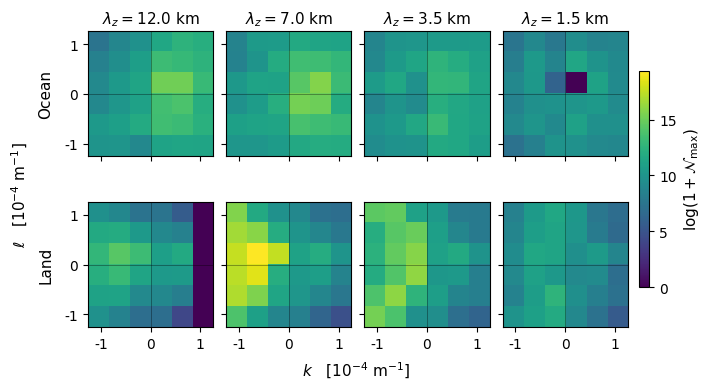

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np


def plot_spectral_bins(
    field_ocean,
    field_land,
    k,
    l,
    m,
    cbar_label,
    savename,
    cmap="RdBu_r",
    log_transform=False,
    vmin=None,
    vmax=None,
    symmetric=False,
    fontsize=11,
    n_ticks=3,
):
    field_ocean = np.nan_to_num(field_ocean, nan=0.0)
    field_land = np.nan_to_num(field_land, nan=0.0)

    if log_transform:
        field_ocean = np.log10(1 + field_ocean)
        field_land = np.log10(1 + field_land)

    if vmin is None or vmax is None:
        data_min = min(field_ocean.min(), field_land.min())
        data_max = max(field_ocean.max(), field_land.max())
        if vmin is None:
            vmin = data_min
        if vmax is None:
            vmax = data_max

    if symmetric:
        vabs = max(abs(vmin), abs(vmax))
        vmin, vmax = -vabs, vabs

    extent = [k.min(), k.max(), l.min(), l.max()]
    nm = len(m)

    fig, axes = plt.subplots(
        2,
        nm,
        figsize=(7.0, 3.8),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if nm == 1:
        axes = axes.reshape(2, 1)

    for j in range(nm):
        lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
        fields = [field_ocean[:, :, j], field_land[:, :, j]]

        for i in range(2):
            ax = axes[i, j]

            im = ax.imshow(
                fields[i].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )

            ax.axhline(0, color="k", lw=0.6, alpha=0.4)
            ax.axvline(0, color="k", lw=0.6, alpha=0.4)

            # Subpanel headers
            if i == 0:
                ax.set_title(
                    rf"$\lambda_z = {lambda_km:.1f}\text{{ km}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            # Row identity labels (Ocean / Land)
            if j == 0:
                label_prefix = "Ocean" if i == 0 else "Land"
                ax.set_ylabel(label_prefix, fontsize=fontsize, labelpad=8)

            # Tick locators
            ax.xaxis.set_major_locator(mticker.MaxNLocator(n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(n_ticks))

            # Integer tick formatting (-1, 0, 1)
            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

    # Single centered figure-level axis labels
    fig.supxlabel(r"$k \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)
    fig.supylabel(r"$\ell \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)

    # Colorbar
    cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()

plot_spectral_bins(
    field_ocean=max_y_train_ocean,
    field_land=max_y_train_land,
    k=k,
    l=l,
    m=m,
    cbar_label=r"$\log(1 + \mathcal{N}_{\mathrm{max}})$",
    savename="MaxSpectrum_OceanLand",
    cmap="viridis",
    log_transform=False,
)

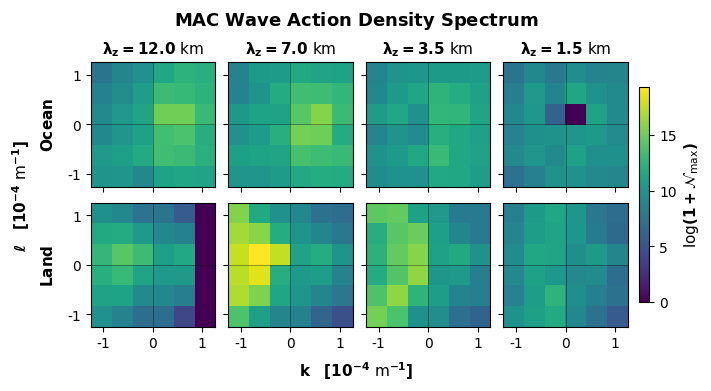

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np


def plot_spectral_bins(
    field_ocean,
    field_land,
    k,
    l,
    m,
    cbar_label,
    savename,
    cmap="RdBu_r",
    log_transform=False,
    vmin=None,
    vmax=None,
    symmetric=False,
    fontsize=11,
    n_ticks=3,
):
    field_ocean = np.nan_to_num(field_ocean, nan=0.0)
    field_land = np.nan_to_num(field_land, nan=0.0)

    if log_transform:
        field_ocean = np.log10(1 + field_ocean)
        field_land = np.log10(1 + field_land)

    if vmin is None or vmax is None:
        data_min = min(field_ocean.min(), field_land.min())
        data_max = max(field_ocean.max(), field_land.max())
        if vmin is None:
            vmin = data_min
        if vmax is None:
            vmax = data_max

    if symmetric:
        vabs = max(abs(vmin), abs(vmax))
        vmin, vmax = -vabs, vabs

    extent = [k.min(), k.max(), l.min(), l.max()]
    nm = len(m)

    fig, axes = plt.subplots(
        2,
        nm,
        figsize=(7.0, 3.8),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if nm == 1:
        axes = axes.reshape(2, 1)

    for j in range(nm):
        lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
        fields = [field_ocean[:, :, j], field_land[:, :, j]]

        for i in range(2):
            ax = axes[i, j]

            im = ax.imshow(
                fields[i].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )

            ax.axhline(0, color="k", lw=0.6, alpha=0.4)
            ax.axvline(0, color="k", lw=0.6, alpha=0.4)

            # Subpanel headers (Bolded)
            if i == 0:
                ax.set_title(
                    rf"$\mathbf{{\lambda_z = {lambda_km:.1f}\text{{ km}}}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            # Row identity labels (Ocean / Land - Bolded)
            if j == 0:
                label_prefix = "Ocean" if i == 0 else "Land"
                ax.set_ylabel(
                    rf"$\mathbf{{{label_prefix}}}$",
                    fontsize=fontsize,
                    labelpad=8,
                )

            # Tick locators
            ax.xaxis.set_major_locator(mticker.MaxNLocator(n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(n_ticks))

            # Integer tick formatting (-1, 0, 1)
            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

    # Figure-level Title
    fig.suptitle(
        r"$\mathbf{MAC\ Wave\ Action\ Density\ Spectrum}$",
        fontsize=fontsize + 2,
        fontweight="bold",
    )

    # Single centered figure-level axis labels (Bolded)
    fig.supxlabel(
        r"$\mathbf{k \quad [10^{-4}\text{ m}^{-1}]}$", fontsize=fontsize
    )
    fig.supylabel(
        r"$\mathbf{\ell \quad [10^{-4}\text{ m}^{-1}]}$", fontsize=fontsize
    )

    # Colorbar (Bolded label)
    cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="bold")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


plot_spectral_bins(
    field_ocean=max_y_train_ocean,
    field_land=max_y_train_land,
    k=k,
    l=l,
    m=m,
    cbar_label=r"$\mathbf{\log(1 + \mathcal{N}_{\mathrm{max}})}$",
    savename="MaxSpectrum_OceanLand",
    cmap="viridis",
    log_transform=False,
)

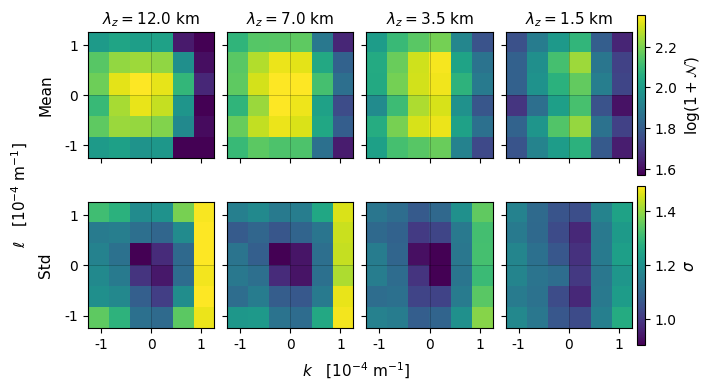

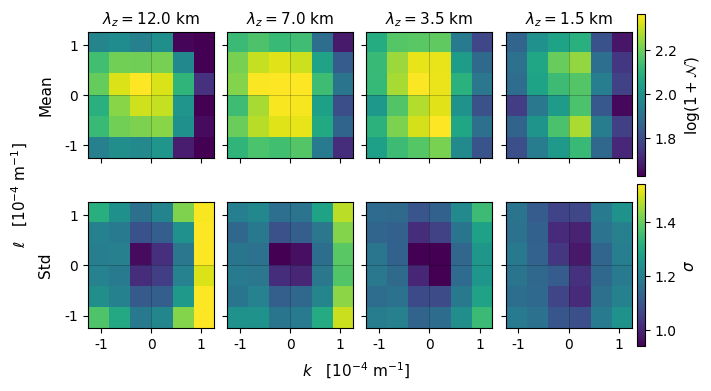

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np


def plot_mean_std_single_domain(
    mean_field,  # array [nk, nl, nm]
    std_field,  # array [nk, nl, nm]
    k,
    l,
    m,
    domain_name,  # "Ocean" or "Land"
    savename,
    cmap="viridis",
    vlim_mean=None,  # (vmin, vmax) in log space
    vlim_std=None,  # (vmin, vmax) in log space
    use_percentile=True,
    fontsize=11,  # Standard paper size (9–11 pt)
    n_ticks=3,
):
    rows = ["Mean", "Std"]
    raw_fields = [mean_field, std_field]

    # Standard LaTeX math labels (no forced bolding)
    cbar_labels = [r"$\log(1+\mathcal{N})$", r"$\sigma$"]

    # Log-transform once up front
    log_fields = [np.log1p(f) for f in raw_fields]

    def auto_vlim(arr):
        if use_percentile:
            return (np.nanpercentile(arr, 2), np.nanpercentile(arr, 98))
        return (np.nanmin(arr), np.nanmax(arr))

    vlims = [
        vlim_mean if vlim_mean is not None else auto_vlim(log_fields[0]),
        vlim_std if vlim_std is not None else auto_vlim(log_fields[1]),
    ]

    nm = len(m)
    n_rows = len(rows)

    # Standard publication width & compact height
    fig, axes = plt.subplots(
        n_rows,
        nm,
        figsize=(7.0, 3.8),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if nm == 1:
        axes = axes.reshape(n_rows, 1)

    extent = [k.min(), k.max(), l.min(), l.max()]

    for row, (row_name, log_field, (vmin, vmax)) in enumerate(
        zip(rows, log_fields, vlims)
    ):
        im = None

        for j in range(nm):
            lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
            ax = axes[row, j]

            im = ax.imshow(
                log_field[:, :, j].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )
            ax.axhline(0, color="k", lw=0.5, alpha=0.3)
            ax.axvline(0, color="k", lw=0.5, alpha=0.3)

            # Subpanel column headers (top row only)
            if row == 0:
                ax.set_title(
                    rf"$\lambda_z = {lambda_km:.1f}\text{{ km}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            # Row identity label ("Mean" / "Std") on leftmost axis
            if j == 0:
                ax.set_ylabel(row_name, fontsize=fontsize, labelpad=8)

            # Tick locators
            ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=n_ticks))

            # Integer tick formatting (-1, 0, 1) to match Option 2
            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

        # Row colorbars with regular weight labels
        cbar = fig.colorbar(im, ax=axes[row, :], fraction=0.02, pad=0.01)
        cbar.set_label(cbar_labels[row], fontsize=fontsize, fontweight="normal")
        cbar.ax.tick_params(labelsize=fontsize - 1)

    # Single centered figure-level axis labels
    fig.supxlabel(r"$k \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)
    fig.supylabel(r"$\ell \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()
    
plot_mean_std_single_domain(
    mean_field=mean_y_train_ocean, std_field=std_y_train_ocean,
    k=k, l=l, m=m, domain_name="Ocean",
    cmap="viridis",
    vlim_mean=None, vlim_std=None,
    savename="ocean_mean_std_spectral",
)

plot_mean_std_single_domain(
    mean_field=mean_y_train_land, std_field=std_y_train_land,
    k=k, l=l, m=m, domain_name="Land",
    cmap="viridis",
    vlim_mean=None, vlim_std=None,
    savename="land_mean_std_spectral",
)

mse_vmax: 1.8483004601400412
cv_vmax: 0.7658250525556571
Ocean R2 range: 0.45080044270586395 0.9398584470729231
Land R2 range: 0.43974289236417596 0.9343815828172931
Ocean MSE range: 0.5096948701030724 2.0912998523649526
Land MSE range: 0.46212436561089193 2.2086658869575078


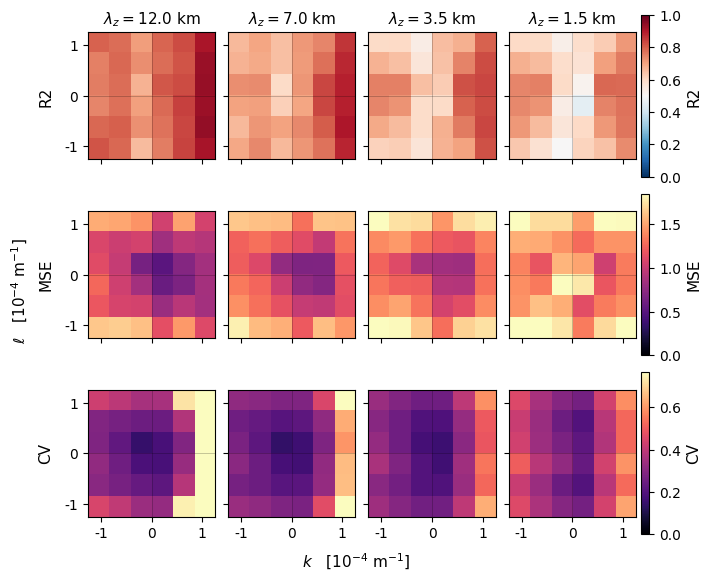

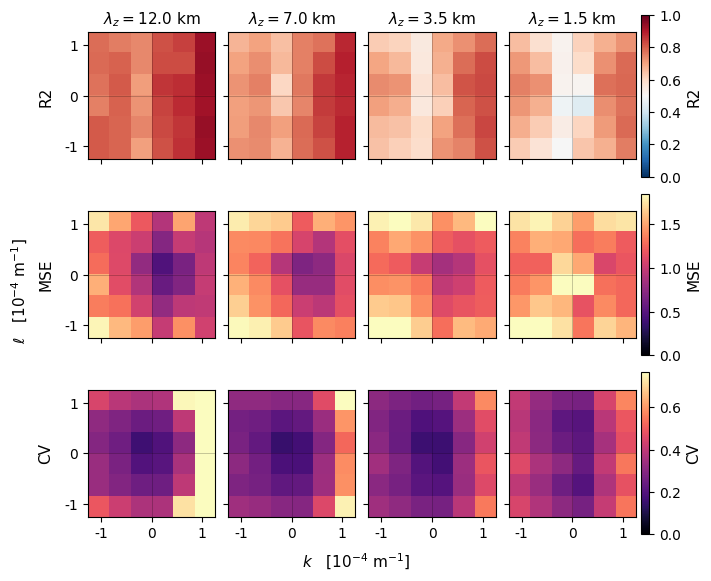

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np


def plot_multi_metric_single_domain(
    fields_dict,
    k,
    l,
    m,
    domain_name,
    cmaps_dict,
    vlims_dict,
    savename,
    fontsize=11,  # Standard paper size (9–11 pt)
    n_ticks=3,
):
    n_metrics = len(fields_dict)
    nm = len(m)

    # Calculate dynamic height based on row count to maintain publication scaling
    fig_height = 1.9 * n_metrics

    fig, axes = plt.subplots(
        n_metrics,
        nm,
        figsize=(7.0, fig_height),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if n_metrics == 1:
        axes = axes.reshape(1, nm)

    extent = [k.min(), k.max(), l.min(), l.max()]

    for row, (metric_name, field) in enumerate(fields_dict.items()):
        cmap = cmaps_dict[metric_name]
        vmin, vmax = vlims_dict[metric_name]
        im = None

        for j in range(nm):
            lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
            ax = axes[row, j]

            im = ax.imshow(
                field[:, :, j].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )
            ax.axhline(0, color="k", lw=0.5, alpha=0.3)
            ax.axvline(0, color="k", lw=0.5, alpha=0.3)

            # Subpanel headers (top row only)
            if row == 0:
                ax.set_title(
                    rf"$\lambda_z = {lambda_km:.1f}\text{{ km}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            # Row identity label (e.g. R2, MSE, CV) on leftmost axis
            if j == 0:
                ax.set_ylabel(metric_name, fontsize=fontsize, labelpad=8)

            # Tick locators
            ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=n_ticks))

            # Scaled integer tick formatting (-1, 0, 1)
            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

        # Colorbar with unbolded metric label
        cbar = fig.colorbar(im, ax=axes[row, :], fraction=0.02, pad=0.01)
        cbar.set_label(metric_name, fontsize=fontsize, fontweight="normal")
        cbar.ax.tick_params(labelsize=fontsize - 1)

    # Single centered figure-level axis labels
    fig.supxlabel(r"$k \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)
    fig.supylabel(r"$\ell \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()
## spectral bin
R2_score_ocean = metrics_data['ocean']["combined"]["R2_test"].reshape(6, 6, 4)
R2_score_land  = metrics_data['land']["combined"]["R2_test"].reshape(6, 6, 4)
MSE_score_ocean = metrics_data['ocean']["combined"]["mse_test"].reshape(6, 6, 4)
MSE_score_land  = metrics_data['land']["combined"]["mse_test"].reshape(6, 6, 4)
mse_vmax = np.nanpercentile(
    np.concatenate([MSE_score_ocean.ravel(), MSE_score_land.ravel()]), 95
)
cv_vmax = np.nanpercentile(
    np.concatenate([cv_y_train_ocean.ravel(), cv_y_train_land.ravel()]), 95
)

print("mse_vmax:", mse_vmax)
print("cv_vmax:", cv_vmax)
# Check your actual value ranges first
print("Ocean R2 range:", R2_score_ocean.min(), R2_score_ocean.max())
print("Land R2 range:", R2_score_land.min(), R2_score_land.max())
print("Ocean MSE range:", MSE_score_ocean.min(), MSE_score_ocean.max())
print("Land MSE range:", MSE_score_land.min(), MSE_score_land.max())
cmaps_dict = {"R2": "RdBu_r", "MSE": "magma", "CV": "magma"}
vlims_dict = {"R2": (0, 1), "MSE": (0, mse_vmax), "CV": (0, cv_vmax)}
# Usage:
# Ocean panel
plot_multi_metric_single_domain(
    fields_dict={"R2": R2_score_ocean, "MSE": MSE_score_ocean, "CV": cv_y_train_ocean},
    k=k, l=l, m=m,
    domain_name="Ocean",
    cmaps_dict=cmaps_dict,
    vlims_dict=vlims_dict,
    savename="Ocean_Metric_Panel",
)

# Land panel
plot_multi_metric_single_domain(
    fields_dict={"R2": R2_score_land, "MSE": MSE_score_land, "CV": cv_y_train_land},
    k=k, l=l, m=m,
    domain_name="Land",
    cmaps_dict=cmaps_dict,
    vlims_dict=vlims_dict,
    savename="Land_Metric_Panel",
)

In [11]:
print("Ocean R2 min:", R2_score_ocean.min(), "at index", np.unravel_index(np.argmin(R2_score_ocean), R2_score_ocean.shape))
print("Ocean R2 max:", R2_score_ocean.max(), "at index", np.unravel_index(np.argmax(R2_score_ocean), R2_score_ocean.shape))

# Average R2 per lambda_z (you asked if this is needed -- yes, it directly supports your "R2 decreases with shorter lambda_z" claim)
for j, lam in enumerate(m):
    print(f"lambda_z index {j}: mean R2 = {R2_score_ocean[:,:,j].mean():.3f}, "
          f"mean MSE = {MSE_score_ocean[:,:,j].mean():.3f}, mean CV = {cv_y_train_ocean[:,:,j].mean():.3f}")

from scipy.stats import spearmanr
import numpy as np

def compute_spearman_table(R2, MSE, CV, label=""):
    r2_flat = R2.ravel()
    mse_flat = MSE.ravel()
    cv_flat = CV.ravel()

    rho_mse, p_mse = spearmanr(mse_flat, r2_flat)
    rho_cv, p_cv = spearmanr(cv_flat, r2_flat)

    print(f"=== {label} ===")
    print(f"Spearman rho(MSE, R2) = {rho_mse:.3f}, p = {p_mse:.3e}")
    print(f"Spearman rho(CV, R2)  = {rho_cv:.3f}, p = {p_cv:.3e}")

    return {
        "rho_mse_r2": rho_mse, "p_mse_r2": p_mse,
        "rho_cv_r2": rho_cv, "p_cv_r2": p_cv,
    }

# --- Ocean ---
ocean_results = compute_spearman_table(
    R2_score_ocean, MSE_score_ocean, cv_y_train_ocean, label="OCEAN"
)

# --- Land ---
land_results = compute_spearman_table(
    R2_score_land, MSE_score_land, cv_y_train_land, label="LAND"
)

Ocean R2 min: 0.45080044270586395 at index (3, 2, 3)
Ocean R2 max: 0.9398584470729231 at index (5, 1, 0)
lambda_z index 0: mean R2 = 0.799, mean MSE = 1.069, mean CV = 0.437
lambda_z index 1: mean R2 = 0.741, mean MSE = 1.237, mean CV = 0.339
lambda_z index 2: mean R2 = 0.691, mean MSE = 1.365, mean CV = 0.317
lambda_z index 3: mean R2 = 0.653, mean MSE = 1.536, mean CV = 0.380
=== OCEAN ===
Spearman rho(MSE, R2) = -0.446, p = 2.169e-08
Spearman rho(CV, R2)  = 0.552, p = 7.312e-13
=== LAND ===
Spearman rho(MSE, R2) = -0.585, p = 1.362e-14
Spearman rho(CV, R2)  = 0.550, p = 9.505e-13


In [12]:
import numpy as np

# Zonal (k) asymmetry: compare negative-k half vs positive-k half
# (excluding center column if grid has odd symmetry; adjust indices to your actual grid)
neg_k = slice(0, 3)   # k indices 0,1,2 = negative k
pos_k = slice(3, 6)   # k indices 3,4,5 = positive k

for name, arr in [("R2", R2_score_ocean), ("MSE", MSE_score_ocean), ("CV", cv_y_train_ocean)]:
    mean_neg_k = arr[neg_k, :, :].mean()
    mean_pos_k = arr[pos_k, :, :].mean()
    print(f"{name}: mean(negative k) = {mean_neg_k:.4f}, mean(positive k) = {mean_pos_k:.4f}, "
          f"diff = {mean_pos_k - mean_neg_k:+.4f}")

print()

# Meridional (l) symmetry: compare negative-l half vs positive-l half
neg_l = slice(0, 3)
pos_l = slice(3, 6)

for name, arr in [("R2", R2_score_ocean), ("MSE", MSE_score_ocean), ("CV", cv_y_train_ocean)]:
    mean_neg_l = arr[:, neg_l, :].mean()
    mean_pos_l = arr[:, pos_l, :].mean()
    print(f"{name}: mean(negative l) = {mean_neg_l:.4f}, mean(positive l) = {mean_pos_l:.4f}, "
          f"diff = {mean_pos_l - mean_neg_l:+.4f}")

R2: mean(negative k) = 0.6781, mean(positive k) = 0.7641, diff = +0.0860
MSE: mean(negative k) = 1.4019, mean(positive k) = 1.2017, diff = -0.2002
CV: mean(negative k) = 0.2951, mean(positive k) = 0.4415, diff = +0.1463

R2: mean(negative l) = 0.7227, mean(positive l) = 0.7195, diff = -0.0032
MSE: mean(negative l) = 1.3194, mean(positive l) = 1.2842, diff = -0.0352
CV: mean(negative l) = 0.3771, mean(positive l) = 0.3596, diff = -0.0175


In [13]:
from scipy.stats import spearmanr
import numpy as np

# Flatten each 6x6x4 grid to compare land vs ocean directly, bin-by-bin
r2_ocean_flat = R2_score_ocean.ravel()
r2_land_flat = R2_score_land.ravel()
mse_ocean_flat = MSE_score_ocean.ravel()
mse_land_flat = MSE_score_land.ravel()
cv_ocean_flat = cv_y_train_ocean.ravel()
cv_land_flat = cv_y_train_land.ravel()

for name, a, b in [("R2", r2_ocean_flat, r2_land_flat),
                     ("MSE", mse_ocean_flat, mse_land_flat),
                     ("CV", cv_ocean_flat, cv_land_flat)]:
    rho, p = spearmanr(a, b)
    mean_abs_diff = np.mean(np.abs(a - b))
    print(f"{name}: Spearman(ocean,land) rho={rho:.3f}, p={p:.2e}, "
          f"mean|ocean-land|={mean_abs_diff:.4f}, "
          f"ocean_mean={a.mean():.3f}, land_mean={b.mean():.3f}")

R2: Spearman(ocean,land) rho=0.965, p=1.50e-84, mean|ocean-land|=0.0232, ocean_mean=0.721, land_mean=0.731
MSE: Spearman(ocean,land) rho=0.934, p=3.61e-65, mean|ocean-land|=0.0959, ocean_mean=1.302, land_mean=1.322
CV: Spearman(ocean,land) rho=0.988, p=4.18e-116, mean|ocean-land|=0.0208, ocean_mean=0.368, land_mean=0.365


In [14]:
import pandas as pd
import numpy as np

def build_metrics_table(k, l, m, r2, mse, cv, mean, std):
    """
    Builds a long-format table with one row per (k, l, m) bin.
    r2, mse, cv, mean, std: arrays of shape (len(k), len(l), len(m))
    """
    rows = []
    for ik, kval in enumerate(k):
        for il, lval in enumerate(l):
            for im, mval in enumerate(m):
                rows.append({
                    "k": kval,
                    "l": lval,
                    "m": mval,
                    "Mean": mean[ik, il, im],
                    "Std": std[ik, il, im],
                    "R2": r2[ik, il, im],
                    "MSE": mse[ik, il, im],
                    "CV": cv[ik, il, im],
                })
    return pd.DataFrame(rows)


# --- Ocean table ---
df_ocean = build_metrics_table(
    k=k, l=l, m=m,
    r2=R2_score_ocean, mse=MSE_score_ocean, cv=cv_y_train_ocean,
    mean=mean_y_train_ocean, std=std_y_train_ocean,
)
print("=== OCEAN ===")
print(df_ocean.to_string(index=False))

# --- Land table ---
df_land = build_metrics_table(
    k=k, l=l, m=m,
    r2=R2_score_land, mse=MSE_score_land, cv=cv_y_train_land,
    mean=mean_y_train_land, std=std_y_train_land,
)
print("\n=== LAND ===")
print(df_land.to_string(index=False))

# Optional: save each to CSV
df_ocean.to_csv("/work/bb1097/b383521/plots/paper_plots/ocean_bin_metrics.csv", index=False)
df_land.to_csv("/work/bb1097/b383521/plots/paper_plots/land_bin_metrics.csv", index=False)

=== OCEAN ===
        k         l        m      Mean      Std       R2      MSE       CV
-0.000126 -0.000126 0.000524  6.382646 2.846905 0.814822 1.634825 0.446038
-0.000126 -0.000126 0.000898  7.162068 2.372732 0.693811 1.795109 0.331291
-0.000126 -0.000126 0.001795  6.504672 2.202414 0.614515 1.924069 0.338590
-0.000126 -0.000126 0.004189  4.898828 2.256333 0.635316 1.915795 0.460586
-0.000126 -0.000063 0.000524  7.669511 2.312448 0.785958 1.186998 0.301512
-0.000126 -0.000063 0.000898  7.787633 2.050725 0.661841 1.418170 0.263331
-0.000126 -0.000063 0.001795  6.824844 2.052869 0.689340 1.414639 0.300794
-0.000126 -0.000063 0.004189  5.170630 2.160604 0.717280 1.430487 0.417861
-0.000126 -0.000042 0.000524  7.162416 2.266117 0.744676 1.259595 0.316390
-0.000126 -0.000042 0.000898  7.024292 2.127018 0.702455 1.335673 0.302809
-0.000126 -0.000042 0.001795  6.031650 2.175623 0.743401 1.314457 0.360701
-0.000126 -0.000042 0.004189  4.420710 2.224743 0.738306 1.410790 0.503255
-0.000126  

In [15]:
from scipy.stats import spearmanr

rho, p = spearmanr(df_ocean["MSE"], df_ocean["R2"])
print(f"Ocean: Spearman rho(MSE, R2) = {rho:.3f}, p = {p:.4g}")

rho, p = spearmanr(df_land["MSE"], df_land["R2"])
print(f"Land: Spearman rho(MSE, R2) = {rho:.3f}, p = {p:.4g}")
rho_cv, p_cv = spearmanr(df_ocean["CV"], df_ocean["R2"])
print(f"Ocean: Spearman rho(CV, R2) = {rho_cv:.3f}, p = {p_cv:.4g}")

rho_cv, p_cv = spearmanr(df_land["CV"], df_land["R2"])
print(f"Land: Spearman rho(CV, R2) = {rho_cv:.3f}, p = {p_cv:.4g}")

Ocean: Spearman rho(MSE, R2) = -0.446, p = 2.169e-08
Land: Spearman rho(MSE, R2) = -0.585, p = 1.362e-14
Ocean: Spearman rho(CV, R2) = 0.552, p = 7.312e-13
Land: Spearman rho(CV, R2) = 0.550, p = 9.505e-13


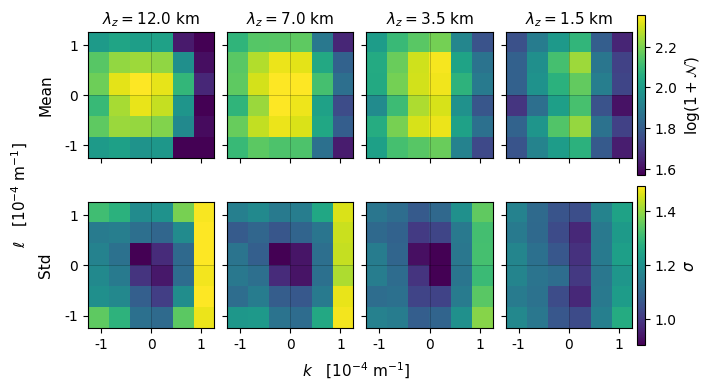

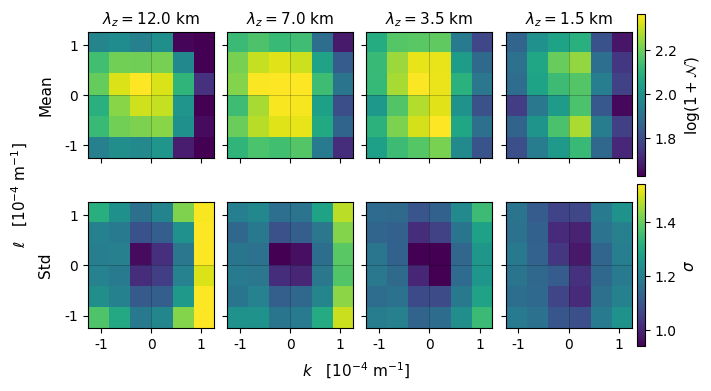

In [16]:
plot_mean_std_single_domain(
    mean_field=mean_y_train_ocean, std_field=std_y_train_ocean,
    k=k, l=l, m=m, domain_name="Ocean",
    cmap="viridis",
    vlim_mean=None, vlim_std=None,
    savename="ocean_mean_std_spectral",
)

plot_mean_std_single_domain(
    mean_field=mean_y_train_land, std_field=std_y_train_land,
    k=k, l=l, m=m, domain_name="Land",
    cmap="viridis",
    vlim_mean=None, vlim_std=None,
    savename="land_mean_std_spectral",
)

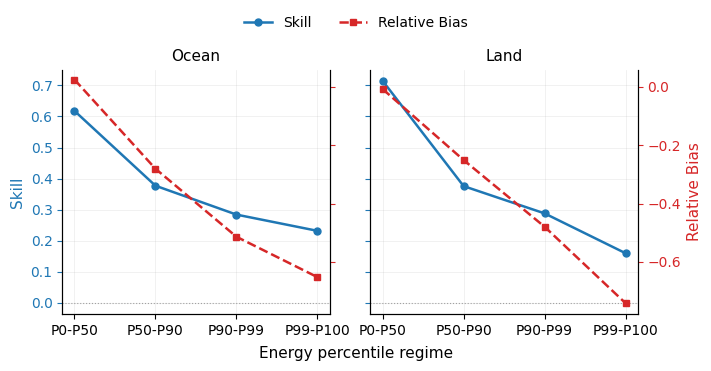

In [17]:
import matplotlib.pyplot as plt
import numpy as np


def plot_skill_bias_dual_axis(
    A_ocean, A_land, savename="ocean_land_skill_bias", fontsize=11
):
    """A_ocean, A_land: lists of dicts with keys 'regime', 'Skill', 'RelBias'"""
    # Standard 2-column paper width (7.0 in)
    fig, axes = plt.subplots(
        1, 2, figsize=(7.0, 3.2), sharey=True, constrained_layout=True
    )

    datasets = [("Ocean", A_ocean, axes[0]), ("Land", A_land, axes[1])]

    skill_color = "#1f77b4"
    bias_color = "#d62728"

    right_axes = []
    handles = []

    for i, (name, A, ax1) in enumerate(datasets):
        regimes = [d["regime"] for d in A]
        skill = [d["Skill"] for d in A]
        relbias = [d["RelBias"] for d in A]
        x = np.arange(len(regimes))

        ax2 = ax1.twinx()
        right_axes.append(ax2)

        ax1.axhline(0, color="gray", lw=0.8, ls=":", alpha=0.7)

        (l1,) = ax1.plot(
            x,
            skill,
            "o-",
            color=skill_color,
            lw=1.8,
            markersize=5,
            label="Skill",
        )
        (l2,) = ax2.plot(
            x,
            relbias,
            "s--",
            color=bias_color,
            lw=1.8,
            markersize=5,
            label="Relative Bias",
        )

        ax1.set_xticks(x)
        ax1.set_xticklabels(regimes, fontsize=fontsize - 1, rotation=0)

        # Unbolded subpanel headers
        ax1.set_title(name, fontsize=fontsize, pad=6)

        # Axis labels (unbolded)
        if i == 0:
            ax1.set_ylabel("Skill", color=skill_color, fontsize=fontsize)
            handles = [l1, l2]
        if i == 1:
            ax2.set_ylabel(
                "Relative Bias", color=bias_color, fontsize=fontsize
            )

        # Colored tick marks and regular font weights for labels
        ax1.tick_params(
            axis="y",
            colors=skill_color,
            labelcolor=skill_color,
            labelsize=fontsize - 1,
        )
        ax2.tick_params(
            axis="y",
            colors=bias_color,
            labelcolor=bias_color,
            labelsize=fontsize - 1,
        )

        ax1.grid(alpha=0.25, lw=0.5)
        ax1.spines["top"].set_visible(False)
        ax2.spines["top"].set_visible(False)

    # Match right-axis limits across both panels
    ylims = [ax.get_ylim() for ax in right_axes]
    ymin = min(l[0] for l in ylims)
    ymax = max(l[1] for l in ylims)
    for ax in right_axes:
        ax.set_ylim(ymin, ymax)

    # Hide right-axis tick labels on the left panel
    right_axes[0].tick_params(labelright=False)

    # Centered figure-level x-axis label (unbolded)
    fig.supxlabel("Energy percentile regime", fontsize=fontsize)

    # Clean upper legend
    fig.legend(
        handles=handles,
        labels=["Skill", "Relative Bias"],
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.01),
        fontsize=fontsize - 1,
        frameon=False,
    )

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()

# --- Usage ---
A_ocean = regimes["ocean"]["combined"]
A_land = regimes["land"]["combined"]

plot_skill_bias_dual_axis(A_ocean, A_land, savename="ocean_land_skill_bias")

Log-space bias (ocean): [0.13421873949795954, -0.0690301611065408, -0.34923291296057046, -0.6859267608807018]
Log-space bias (land): [0.08118678524203361, -0.05635942967161115, -0.284539666127342, -0.6048704773198942]
Real-space RelBias (ocean): [0.024633686021827014, -0.28084963798330925, -0.5138886313931063, -0.6522496581271489]
Real-space RelBias (land): [-0.007849034520573341, -0.2511093679897214, -0.4796522277276494, -0.7416114749600875]


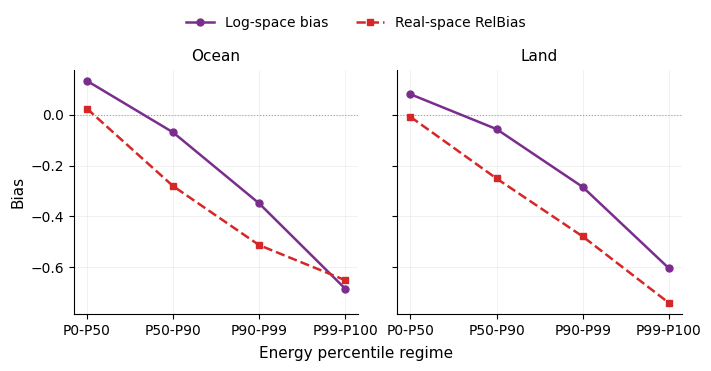

In [18]:
import numpy as np
import matplotlib.pyplot as plt

### Examine bias due to log transform
y_test_land_log = metrics_data["land"]["combined"]["y_test"]
y_pred_land_log = metrics_data["land"]["combined"]["y_pred_test"]
y_test_ocean_log = metrics_data["ocean"]["combined"]["y_test"]
y_pred_ocean_log = metrics_data["ocean"]["combined"]["y_pred_test"]

# Per-sample log-space residual (mean over the 144 spectral dims) -> shape (n_samples,)
log_resid_ocean = np.mean(y_pred_ocean_log - y_test_ocean_log, axis=1)
log_resid_land  = np.mean(y_pred_land_log  - y_test_land_log,  axis=1)

# Back-transform to real space (per-bin, still shape (n_samples, 144))
y_test_land_orig  = np.expm1(y_test_land_log)
y_pred_land_orig  = np.expm1(y_pred_land_log)
y_test_ocean_orig = np.expm1(y_test_ocean_log)
y_pred_ocean_orig = np.expm1(y_pred_ocean_log)

# Per-sample TOTAL energy (must match your regime table's energy definition)
E_test_ocean = y_test_ocean_orig.sum(axis=1)
E_test_land  = y_test_land_orig.sum(axis=1)

## define regime bounds + pull RelBias straight from the existing regimes dict
regimes_labels = ["P0-P50", "P50-P90", "P90-P99", "P99-P100"]
tags = ["land", "ocean"]
regime_bounds = {}
relbias_table = {}
for tag in tags:
    regime_bounds[tag] = []
    relbias_table[tag] = []
    for i, regime in enumerate(regimes_labels):
        E_min = regimes[tag]["combined"][i]["E_min"]
        E_max = regimes[tag]["combined"][i]["E_max"]
        regime_bounds[tag].append((regime, E_min, E_max))
        relbias_table[tag].append(regimes[tag]["combined"][i]["RelBias"])

# --- Compute log-space bias per regime (this is the new part) ---
logbias_table = {"ocean": [], "land": []}

for name, lo, hi in regime_bounds["ocean"]:
    mask = (E_test_ocean >= lo) & (E_test_ocean < hi)
    logbias_table["ocean"].append(np.mean(log_resid_ocean[mask]))

for name, lo, hi in regime_bounds["land"]:
    mask = (E_test_land >= lo) & (E_test_land < hi)
    logbias_table["land"].append(np.mean(log_resid_land[mask]))

print("Log-space bias (ocean):", logbias_table["ocean"])
print("Log-space bias (land):", logbias_table["land"])
print("Real-space RelBias (ocean):", relbias_table["ocean"])
print("Real-space RelBias (land):", relbias_table["land"])


import matplotlib.pyplot as plt
import numpy as np


def plot_logspace_vs_realspace_bias(
    regime_labels,
    logbias_ocean,
    relbias_ocean,
    logbias_land,
    relbias_land,
    savename="logspace_vs_realspace_bias",
    fontsize=11,  # Standard paper font size (9–11 pt)
):
    # Standard 2-column paper figure dimensions
    fig, axes = plt.subplots(
        1, 2, figsize=(7.0, 3.2), sharey=True, constrained_layout=True
    )

    datasets = [
        ("Ocean", logbias_ocean, relbias_ocean, axes[0]),
        ("Land", logbias_land, relbias_land, axes[1]),
    ]

    logbias_color = "#7b2d8e"
    relbias_color = "#d62728"
    x = np.arange(len(regime_labels))
    handles = []

    for i, (name, logbias, relbias, ax) in enumerate(datasets):
        ax.axhline(0, color="gray", lw=0.8, ls=":", alpha=0.7)

        (l1,) = ax.plot(
            x,
            logbias,
            "o-",
            color=logbias_color,
            lw=1.8,
            markersize=5,
            label="Log-space bias",
        )
        (l2,) = ax.plot(
            x,
            relbias,
            "s--",
            color=relbias_color,
            lw=1.8,
            markersize=5,
            label="Real-space RelBias",
        )

        ax.set_xticks(x)
        ax.set_xticklabels(regime_labels, fontsize=fontsize - 1, rotation=0)

        # Unbolded subpanel headers
        ax.set_title(name, fontsize=fontsize, pad=6)

        ax.tick_params(axis="both", labelsize=fontsize - 1)
        ax.grid(alpha=0.25, lw=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if i == 0:
            ax.set_ylabel("Bias", fontsize=fontsize)
            handles = [l1, l2]

    # Centered figure-level x-axis label (unbolded)
    fig.supxlabel("Energy percentile regime", fontsize=fontsize)

    # Clean upper legend
    fig.legend(
        handles=handles,
        labels=["Log-space bias", "Real-space RelBias"],
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.01),
        fontsize=fontsize - 1,
        frameon=False,
    )

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Call statement ---
plot_logspace_vs_realspace_bias(
    regimes_labels,
    logbias_table["ocean"],
    relbias_table["ocean"],
    logbias_table["land"],
    relbias_table["land"],
    savename="logspace_vs_realspace_bias",
)

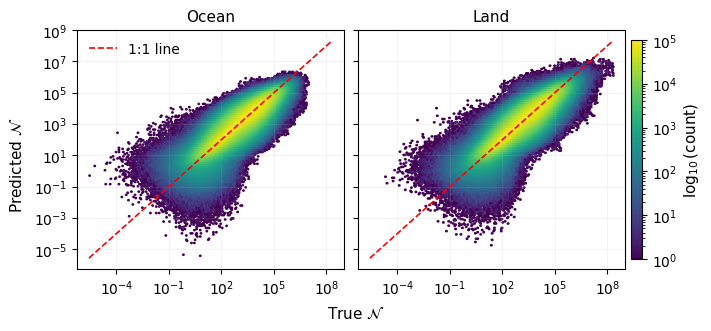

In [19]:
import matplotlib.pyplot as plt
import numpy as np


def plot_parity_side_by_side(
    y_true_ocean,
    y_pred_ocean,
    y_true_land,
    y_pred_land,
    savename="parity_ocean_land",
    fontsize=11,  # Standard paper font size (9–11 pt)
    bins=150,
):
    """y_true_*, y_pred_*: real-space arrays, any shape -- will be raveled."""
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(7.0, 3.2),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    datasets = [
        ("Ocean", y_true_ocean, y_pred_ocean, axes[0]),
        ("Land", y_true_land, y_pred_land, axes[1]),
    ]

    # Pre-calculate global min/max counts for a shared colorbar scale
    processed_data = []
    global_min_val = float("inf")
    global_max_val = float("-inf")

    for name, y_true_orig, y_pred_orig, ax in datasets:
        y_true_flat = y_true_orig.ravel()
        y_pred_flat = np.maximum(y_pred_orig.ravel(), 0)

        mask = (y_true_flat > 0) & (y_pred_flat > 0)
        yt = y_true_flat[mask]
        yp = y_pred_flat[mask]

        global_min_val = min(global_min_val, yt.min(), yp.min())
        global_max_val = max(global_max_val, yt.max(), yp.max())
        processed_data.append((name, yt, yp, ax))

    hb = None
    lims = [global_min_val, global_max_val]

    for name, yt, yp, ax in processed_data:
        hb = ax.hexbin(
            yt,
            yp,
            gridsize=bins,
            xscale="log",
            yscale="log",
            cmap="viridis",
            mincnt=1,
            bins="log",
        )

        ax.plot(lims, lims, "r--", lw=1.2, label="1:1 line")

        # Unbolded subpanel headers
        ax.set_title(name, fontsize=fontsize, pad=6)

        ax.tick_params(axis="both", labelsize=fontsize - 1)
        ax.grid(alpha=0.2, lw=0.5)

        if name == "Ocean":
            ax.legend(fontsize=fontsize - 1, frameon=False, loc="upper left")

    # Single centered figure-level axis labels
    fig.supxlabel(r"True $\mathcal{N}$", fontsize=fontsize)
    fig.supylabel(r"Predicted $\mathcal{N}$", fontsize=fontsize)

    # Shared figure-level colorbar
    cbar = fig.colorbar(hb, ax=axes, fraction=0.02, pad=0.01)
    cbar.set_label(
        r"$\log_{10}(\mathrm{count})$", fontsize=fontsize, fontweight="normal"
    )
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Call statement ---
plot_parity_side_by_side(
    y_test_ocean_orig,
    y_pred_ocean_orig,
    y_test_land_orig,
    y_pred_land_orig,
    savename="parity_ocean_land",
)

In [20]:
import numpy as np

# --- Ocean ---
y_true_flat = y_test_ocean_orig.ravel()
y_pred_flat = np.maximum(y_pred_ocean_orig.ravel(), 0)

mask = (y_true_flat > 0) & (y_pred_flat > 0)
yt = y_true_flat[mask]
yp = y_pred_flat[mask]

threshold = np.percentile(yt, 90)   # 90th percentile of per-bin TRUE magnitude
low_mask = yt < threshold
high_mask = yt >= threshold

resid = yp - yt

print("=== OCEAN ===")
print(f"Threshold (P90 of true N): {threshold:.3f}")
print(f"Low-magnitude bins  (n={low_mask.sum()}): mean bias = {np.mean(resid[low_mask]):.4f}, "
      f"std = {np.std(resid[low_mask]):.4f}")
print(f"High-magnitude bins (n={high_mask.sum()}): mean bias = {np.mean(resid[high_mask]):.4f}, "
      f"std = {np.std(resid[high_mask]):.4f}")

# --- Land (repeat identically) ---
y_true_flat_l = y_test_land_orig.ravel()
y_pred_flat_l = np.maximum(y_pred_land_orig.ravel(), 0)

mask_l = (y_true_flat_l > 0) & (y_pred_flat_l > 0)
yt_l = y_true_flat_l[mask_l]
yp_l = y_pred_flat_l[mask_l]

threshold_l = np.percentile(yt_l, 90)
low_mask_l = yt_l < threshold_l
high_mask_l = yt_l >= threshold_l

resid_l = yp_l - yt_l

print("\n=== LAND ===")
print(f"Threshold (P90 of true N): {threshold_l:.3f}")
print(f"Low-magnitude bins  (n={low_mask_l.sum()}): mean bias = {np.mean(resid_l[low_mask_l]):.4f}, "
      f"std = {np.std(resid_l[low_mask_l]):.4f}")
print(f"High-magnitude bins (n={high_mask_l.sum()}): mean bias = {np.mean(resid_l[high_mask_l]):.4f}, "
      f"std = {np.std(resid_l[high_mask_l]):.4f}")

=== OCEAN ===
Threshold (P90 of true N): 33676.027
Low-magnitude bins  (n=65184501): mean bias = 729.7709, std = 9005.0574
High-magnitude bins (n=7242725): mean bias = -50773.0983, std = 121553.3765

=== LAND ===
Threshold (P90 of true N): 45567.341
Low-magnitude bins  (n=47848250): mean bias = 1143.9496, std = 13713.6617
High-magnitude bins (n=5316473): mean bias = -90677.0602, std = 607562.4814


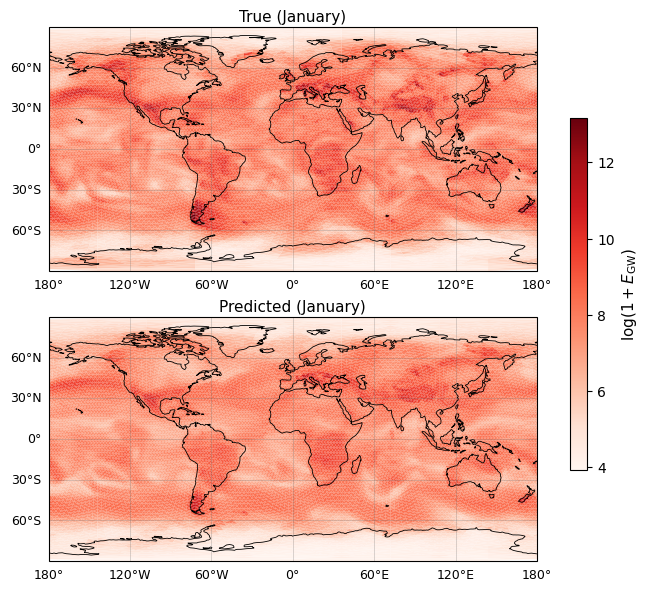

--> saved to /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_jan.png and /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_jan.pdf


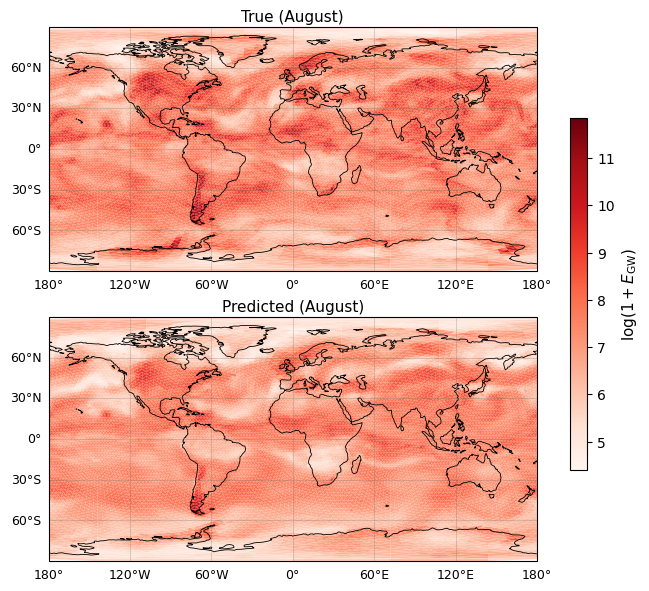

--> saved to /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_aug.png and /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_aug.pdf


In [21]:
import os
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.collections import PolyCollection


def plot_global_map_pair(
    var_top,
    var_bottom,
    save_dir,
    filename="global_flux_map_pair",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\log(1+E_{GW})$",
    cmap="Reds",
    vmin=None,
    vmax=None,
    fontsize=11,  # Standard publication size
):
    gridfil = xr.open_dataset(
        "/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc"
    )

    clon_vertices = np.rad2deg(gridfil.clon_vertices.values)
    clat_vertices = np.rad2deg(gridfil.clat_vertices.values)

    clon_vertices = np.where(
        clon_vertices < -180.0, clon_vertices + 360.0, clon_vertices
    )
    clon_vertices = np.where(
        clon_vertices > 180.0, clon_vertices - 360.0, clon_vertices
    )
    triangles = np.stack([clon_vertices, clat_vertices], axis=-1)

    if vmin is None:
        vmin = min(np.nanmin(var_top), np.nanmin(var_bottom))
    if vmax is None:
        vmax = max(np.nanmax(var_top), np.nanmax(var_bottom))

    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)

    # 2 rows, 1 column for vertical layout (Standard paper width 7.0 in)
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 5.8),
        subplot_kw=dict(projection=ccrs.PlateCarree()),
        constrained_layout=True,
    )

    datasets = [
        (var_top, title_top, axes[0]),
        (var_bottom, title_bottom, axes[1]),
    ]

    for var, subtitle, ax in datasets:
        colors = cmap_obj(norm(var))

        ax.set_global()
        ax.coastlines(linewidth=0.6, zorder=2)

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.4,
            color="dimgray",
            alpha=0.45,
            zorder=2,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": fontsize - 2}
        gl.ylabel_style = {"size": fontsize - 2}

        coll = PolyCollection(
            triangles,
            array=None,
            fc=colors,
            edgecolors="none",
            linewidth=0.05,
            transform=ccrs.Geodetic(),
            zorder=0,
        )
        ax.add_collection(coll)

        # Unbolded subpanel title
        ax.set_title(subtitle, fontsize=fontsize, pad=4)

    # ScalarMappable for colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])

    # Vertical colorbar on the right with compact width and padding
    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation="vertical",
        fraction=0.03,
        pad=0.03,
        shrink=0.85,
    )
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    os.makedirs(save_dir, exist_ok=True)
    outpath_png = os.path.join(save_dir, f"{filename}.png")
    outpath_pdf = os.path.join(save_dir, f"{filename}.pdf")

    plt.savefig(outpath_png, dpi=400, bbox_inches="tight")
    plt.savefig(outpath_pdf, dpi=400, bbox_inches="tight")
    plt.show()
    print(f"--> saved to {outpath_png} and {outpath_pdf}")


# --- Usage: January ---
E_test_jan = np.mean(metrics_data["Energy_test"][:, :22], axis=1)
E_model_jan = np.mean(metrics_data["Energy_model"][:, :22], axis=1)

vmin_jan = min(np.min(np.log1p(E_test_jan)), np.min(np.log1p(E_model_jan)))
vmax_jan = max(np.max(np.log1p(E_test_jan)), np.max(np.log1p(E_model_jan)))

plot_global_map_pair(
    np.log1p(E_test_jan),
    np.log1p(E_model_jan),
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="E_test_vs_model_jan",
    title_top="True (January)",
    title_bottom="Predicted (January)",
    cbar_label=r"$\log(1+E_{\mathrm{GW}})$",
    cmap="Reds",
    vmin=vmin_jan,
    vmax=vmax_jan,
)

# --- Usage: August ---
E_test_aug = np.mean(metrics_data["Energy_test"][:, 22:], axis=1)
E_model_aug = np.mean(metrics_data["Energy_model"][:, 22:], axis=1)

vmin_aug = min(np.min(np.log1p(E_test_aug)), np.min(np.log1p(E_model_aug)))
vmax_aug = max(np.max(np.log1p(E_test_aug)), np.max(np.log1p(E_model_aug)))

plot_global_map_pair(
    np.log1p(E_test_aug),
    np.log1p(E_model_aug),
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="E_test_vs_model_aug",
    title_top="True (August)",
    title_bottom="Predicted (August)",
    cbar_label=r"$\log(1+E_{\mathrm{GW}})$",
    cmap="Reds",
    vmin=vmin_aug,
    vmax=vmax_aug,
)

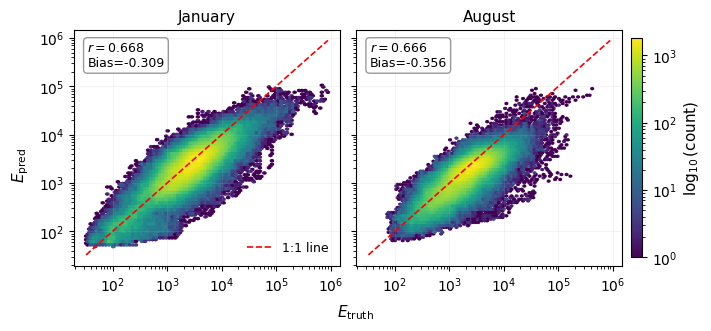

In [22]:
import matplotlib.pyplot as plt
import numpy as np


def plot_energy_scatter_pair(
    E_true_jan,
    E_pred_jan,
    E_true_aug,
    E_pred_aug,
    savename="hexbin_energy_seasons",
    gridsize=80,
    fontsize=11,  # Standard publication size
):
    datasets = [
        ("January", E_true_jan, E_pred_jan, 0),
        ("August", E_true_aug, E_pred_aug, 1),
    ]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(7.0, 3.2),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    # Process data and determine shared global axis limits
    processed_data = []
    global_min = float("inf")
    global_max = float("-inf")

    for title, E_true_full, E_pred_full, idx in datasets:
        E_true = E_true_full.ravel()
        E_pred = E_pred_full.ravel()

        mask = (
            np.isfinite(E_true)
            & np.isfinite(E_pred)
            & (E_true > 0)
            & (E_pred > 0)
        )
        x = E_true[mask]
        y = E_pred[mask]

        r = np.corrcoef(x, y)[0, 1]
        bias = np.mean(y) / np.mean(x) - 1

        global_min = min(global_min, x.min(), y.min())
        global_max = max(global_max, x.max(), y.max())

        processed_data.append((title, x, y, r, bias, axes[idx]))

    lims = [global_min, global_max]
    hb = None

    for title, x, y, r, bias, ax in processed_data:
        hb = ax.hexbin(
            x,
            y,
            gridsize=gridsize,
            bins="log",
            mincnt=1,
            xscale="log",
            yscale="log",
            cmap="viridis",
        )

        ax.plot(lims, lims, "r--", lw=1.2, label="1:1 line")

        # Unbolded subpanel headers
        ax.set_title(title, fontsize=fontsize, pad=6)

        # Statistics annotation box
        ax.text(
            0.05,
            0.95,
            f"$r={r:.3f}$\nBias={bias:.3f}",
            transform=ax.transAxes,
            fontsize=fontsize - 2,
            va="top",
            bbox=dict(
                facecolor="white",
                edgecolor="gray",
                alpha=0.8,
                boxstyle="round,pad=0.3",
            ),
        )

        ax.tick_params(axis="both", labelsize=fontsize - 1)
        ax.grid(alpha=0.2, lw=0.5)

        if title == "January":
            ax.legend(fontsize=fontsize - 2, frameon=False, loc="lower right")

    # Centered figure-level axis labels
    fig.supxlabel(r"$E_{\mathrm{truth}}$", fontsize=fontsize)
    fig.supylabel(r"$E_{\mathrm{pred}}$", fontsize=fontsize)

    # Shared colorbar on the right
    cbar = fig.colorbar(hb, ax=axes, fraction=0.02, pad=0.01)
    cbar.set_label(
        r"$\log_{10}(\mathrm{count})$", fontsize=fontsize, fontweight="normal"
    )
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Usage ---
E_test_jan_full = metrics_data["Energy_test"][:, :22]
E_model_jan_full = metrics_data["Energy_model"][:, :22]
E_test_aug_full = metrics_data["Energy_test"][:, 22:]
E_model_aug_full = metrics_data["Energy_model"][:, 22:]

plot_energy_scatter_pair(
    E_test_jan_full,
    E_model_jan_full,
    E_test_aug_full,
    E_model_aug_full,
    savename="hexbin_energy_seasons",
)

In [23]:
import numpy as np

# Time-averaged (as used for the spatial maps) — real space
E_test_jan_mean = np.mean(metrics_data["Energy_test"][:, :22], axis=1)
E_test_aug_mean = np.mean(metrics_data["Energy_test"][:, 22:], axis=1)

print("=== Time-averaged energy (spatial map basis) ===")
print(f"January: mean E = {E_test_jan_mean.mean():.4e}, max = {E_test_jan_mean.max():.4e}")
print(f"August:  mean E = {E_test_aug_mean.mean():.4e}, max = {E_test_aug_mean.max():.4e}")
print(f"Ratio (Jan/Aug), mean: {E_test_jan_mean.mean() / E_test_aug_mean.mean():.2f}x")
print(f"Ratio (Jan/Aug), max:  {E_test_jan_mean.max() / E_test_aug_mean.max():.2f}x")

# Log-space equivalent (matches what's shown in the colorbar of your spatial maps)
log_E_test_jan = np.log1p(E_test_jan_mean)
log_E_test_aug = np.log1p(E_test_aug_mean)

print("\n=== log(1+E) space (matches map colorbar) ===")
print(f"January: mean log(1+E) = {log_E_test_jan.mean():.3f}, max = {log_E_test_jan.max():.3f}")
print(f"August:  mean log(1+E) = {log_E_test_aug.mean():.3f}, max = {log_E_test_aug.max():.3f}")

# --- Also check using the RAVELED (not time-averaged) energy, matching the hexbin scatter basis ---
E_test_jan_full = metrics_data["Energy_test"][:, :22].ravel()
E_test_aug_full = metrics_data["Energy_test"][:, 22:].ravel()

print("\n=== Full (raveled, not time-averaged) energy, matches hexbin scatter basis ===")
print(f"January: mean E = {E_test_jan_full.mean():.4e}")
print(f"August:  mean E = {E_test_aug_full.mean():.4e}")
print(f"Ratio (Jan/Aug), mean: {E_test_jan_full.mean() / E_test_aug_full.mean():.2f}x")

=== Time-averaged energy (spatial map basis) ===
January: mean E = 4.4837e+03, max = 5.2735e+05
August:  mean E = 2.9016e+03, max = 1.4108e+05
Ratio (Jan/Aug), mean: 1.55x
Ratio (Jan/Aug), max:  3.74x

=== log(1+E) space (matches map colorbar) ===
January: mean log(1+E) = 7.837, max = 13.176
August:  mean log(1+E) = 7.577, max = 11.857

=== Full (raveled, not time-averaged) energy, matches hexbin scatter basis ===
January: mean E = 4.4837e+03
August:  mean E = 2.9016e+03
Ratio (Jan/Aug), mean: 1.55x


Using shared color range: vmin=-8.4924, vmax=8.4924


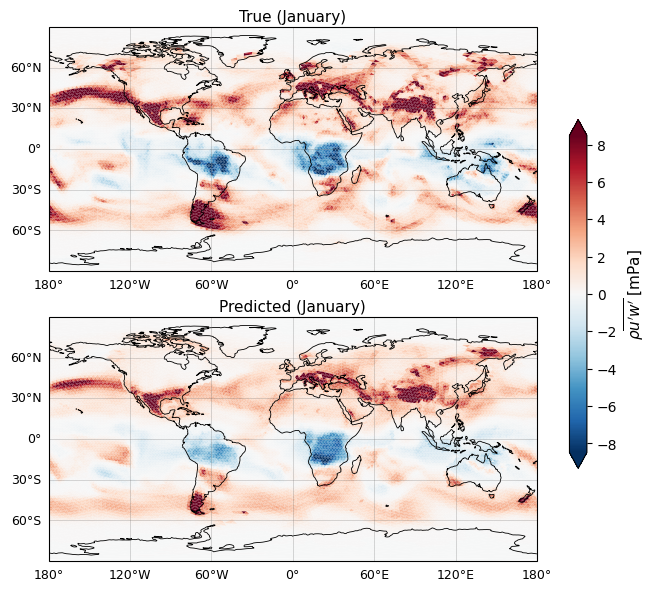

--> saved to /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_jan.png and /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_jan.pdf
Using shared color range: vmin=-3.7979, vmax=3.7979


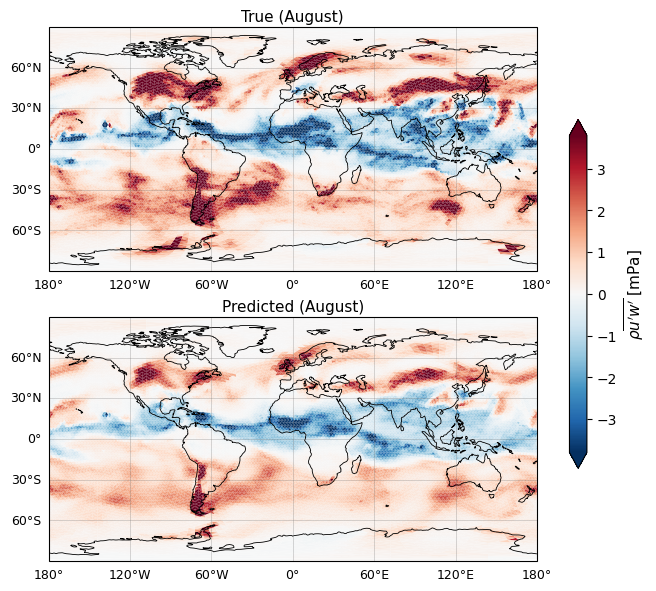

--> saved to /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_aug.png and /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_aug.pdf
Using shared color range: vmin=-2.7116, vmax=2.7116


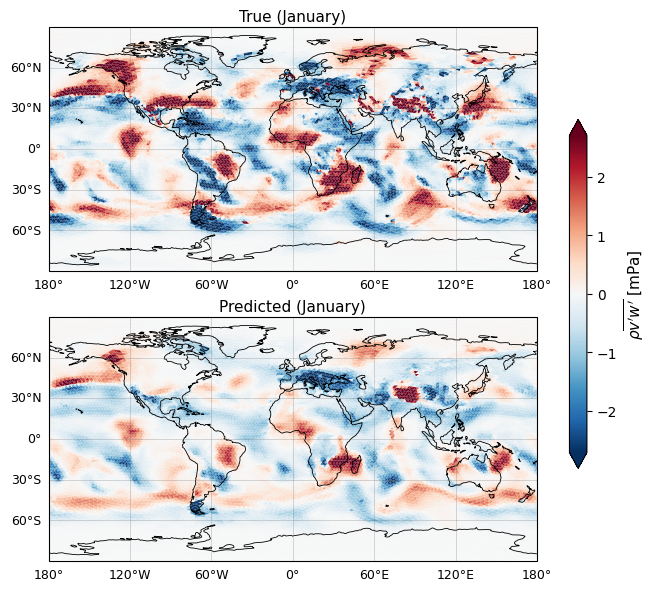

--> saved to /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_jan.png and /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_jan.pdf
Using shared color range: vmin=-2.1318, vmax=2.1318


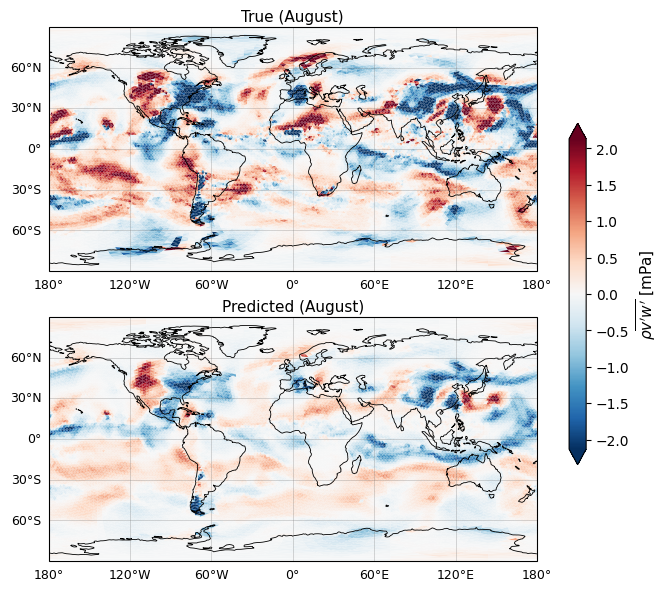

--> saved to /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_aug.png and /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_aug.pdf


In [11]:
import os
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.collections import PolyCollection
from matplotlib.colors import TwoSlopeNorm


def plot_global_map_flux_pair(
    var_top,
    var_bottom,
    save_dir,
    filename="global_momentum_flux_map_pair",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    cmap="RdBu_r",
    vmin=None,
    vmax=None,
    percentile_clip=True,
    p_low=2,
    p_high=98,
    symmetric=True,
    fontsize=11,
):
    var_top = np.asarray(var_top, dtype=float)
    var_bottom = np.asarray(var_bottom, dtype=float)

    gridfil = xr.open_dataset(
        "/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc"
    )
    clon_vertices = np.rad2deg(gridfil.clon_vertices.values)
    clat_vertices = np.rad2deg(gridfil.clat_vertices.values)
    gridfil.close()

    clon_vertices = np.where(
        clon_vertices < -180.0, clon_vertices + 360.0, clon_vertices
    )
    clon_vertices = np.where(
        clon_vertices > 180.0, clon_vertices - 360.0, clon_vertices
    )
    triangles = np.stack([clon_vertices, clat_vertices], axis=-1)

    # ---------------------------
    # Shared color range across BOTH panels
    # ---------------------------
    if vmin is None or vmax is None:
        combined = np.concatenate(
            [var_top[np.isfinite(var_top)], var_bottom[np.isfinite(var_bottom)]]
        )
        if percentile_clip:
            p_lo_val, p_hi_val = np.nanpercentile(combined, [p_low, p_high])
            if symmetric:
                vmax_abs = max(abs(p_lo_val), abs(p_hi_val))
                vmin, vmax = -vmax_abs, vmax_abs
            else:
                vmin, vmax = p_lo_val, p_hi_val
        else:
            vmin, vmax = np.nanmin(combined), np.nanmax(combined)

    print(f"Using shared color range: vmin={vmin:.4f}, vmax={vmax:.4f}")

    cmap_obj = plt.get_cmap(cmap)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    # 2 rows, 1 column vertical stack layout (Standard paper width 7.0 in)
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 5.8),
        subplot_kw=dict(projection=ccrs.PlateCarree()),
        constrained_layout=True,
    )

    datasets = [
        (var_top, title_top, axes[0]),
        (var_bottom, title_bottom, axes[1]),
    ]

    for var, subtitle, ax in datasets:
        colors = cmap_obj(norm(var))
        colors[~np.isfinite(var)] = [1, 1, 1, 0]

        ax.set_global()
        ax.coastlines(linewidth=0.6, zorder=2)

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.4,
            color="dimgray",
            alpha=0.45,
            zorder=2,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": fontsize - 2}
        gl.ylabel_style = {"size": fontsize - 2}

        coll = PolyCollection(
            triangles,
            fc=colors,
            edgecolors="none",
            linewidth=0.05,
            transform=ccrs.Geodetic(),
            zorder=0,
        )
        ax.add_collection(coll)

        # Unbolded subpanel title
        ax.set_title(subtitle, fontsize=fontsize, pad=4)

    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])

    # Vertical colorbar on the right with compact width and padding
    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation="vertical",
        fraction=0.03,
        pad=0.03,
        shrink=0.85,
        extend="both",
    )
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    os.makedirs(save_dir, exist_ok=True)
    outpath_png = os.path.join(save_dir, f"{filename}.png")
    outpath_pdf = os.path.join(save_dir, f"{filename}.pdf")

    plt.savefig(outpath_png, dpi=400, bbox_inches="tight")
    plt.savefig(outpath_pdf, dpi=400, bbox_inches="tight")
    plt.show()
    print(f"--> saved to {outpath_png} and {outpath_pdf}")


# --- Usage: compute all 8 arrays first ---
uw_test_jan = np.mean(
    metrics_data["vw_test"][:, :22] * 1000, axis=1
)  # Pa -> mPa
uw_test_aug = np.mean(metrics_data["vw_test"][:, 22:] * 1000, axis=1)
vw_test_jan = np.mean(metrics_data["uw_test"][:, :22] * 1000, axis=1)
vw_test_aug = np.mean(metrics_data["uw_test"][:, 22:] * 1000, axis=1)
uw_model_jan = np.mean(metrics_data["vw_model"][:, :22] * 1000, axis=1)
uw_model_aug = np.mean(metrics_data["vw_model"][:, 22:] * 1000, axis=1)
vw_model_jan = np.mean(metrics_data["uw_model"][:, :22] * 1000, axis=1)
vw_model_aug = np.mean(metrics_data["uw_model"][:, 22:] * 1000, axis=1)

# --- uw: January ---
plot_global_map_flux_pair(
    uw_test_jan,
    uw_model_jan,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="uw_momentum_flux_mpa_jan",
    title_top="True (January)",
    title_bottom="Predicted (January)",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    symmetric=True,
)

# --- uw: August ---
plot_global_map_flux_pair(
    uw_test_aug,
    uw_model_aug,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="uw_momentum_flux_mpa_aug",
    title_top="True (August)",
    title_bottom="Predicted (August)",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    symmetric=True,
)

# --- vw: January ---
plot_global_map_flux_pair(
    vw_test_jan,
    vw_model_jan,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="vw_momentum_flux_mpa_jan",
    title_top="True (January)",
    title_bottom="Predicted (January)",
    cbar_label=r"$\rho\overline{v'w'}$ [mPa]",
    symmetric=True,
)

# --- vw: August ---
plot_global_map_flux_pair(
    vw_test_aug,
    vw_model_aug,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="vw_momentum_flux_mpa_aug",
    title_top="True (August)",
    title_bottom="Predicted (August)",
    cbar_label=r"$\rho\overline{v'w'}$ [mPa]",
    symmetric=True,
)

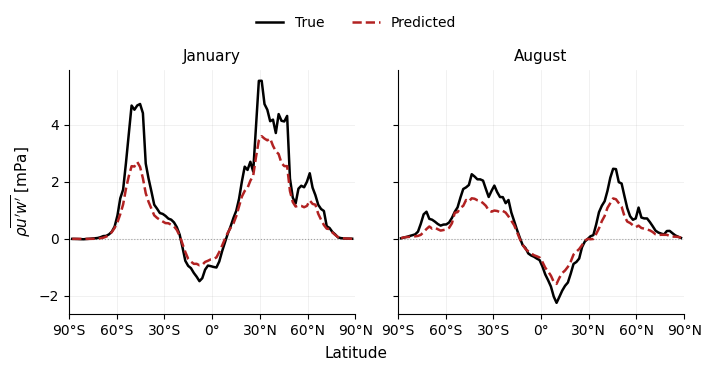

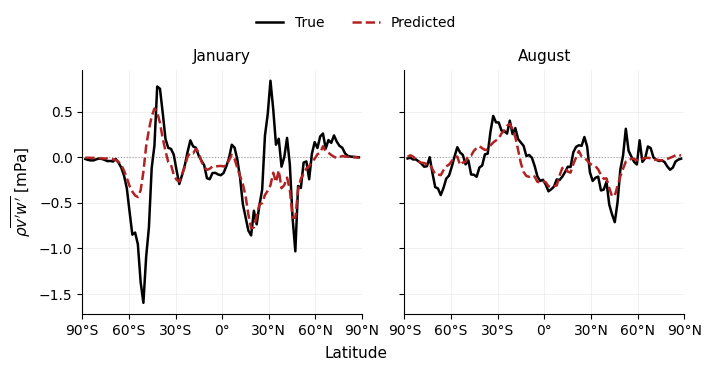

In [10]:
import matplotlib.pyplot as plt
import numpy as np


def plot_zonal_mean_pair(
    lat,
    test_jan,
    model_jan,
    test_aug,
    model_aug,
    ylabel=r"$\rho\overline{u'w'}$ [mPa]",
    savename="zonal_mean_uw",
    fontsize=11,  # Standard paper font size (9–11 pt)
):
    # Standard 2-column paper figure dimensions
    fig, axes = plt.subplots(
        1, 2, figsize=(7.0, 3.2), sharey=True, constrained_layout=True
    )

    datasets = [
        ("January", test_jan, model_jan, axes[0]),
        ("August", test_aug, model_aug, axes[1]),
    ]

    handles = []

    for name, true_vals, pred_vals, ax in datasets:
        ax.axhline(0, color="gray", lw=0.8, ls=":", alpha=0.7)

        (l1,) = ax.plot(lat, true_vals, "-", color="black", lw=1.8, label="True")
        (l2,) = ax.plot(
            lat, pred_vals, "--", color="firebrick", lw=1.8, label="Predicted"
        )

        ax.set_title(name, fontsize=fontsize, pad=6)
        ax.set_xlim(lat.min(), lat.max())

        # Clean degree-formatted latitude ticks
        xticks = np.arange(-90, 91, 30)
        xticklabels = [
            f"{abs(x)}°S" if x < 0 else (f"{x}°N" if x > 0 else "0°")
            for x in xticks
        ]
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, fontsize=fontsize - 1)

        ax.tick_params(axis="both", labelsize=fontsize - 1)
        ax.grid(alpha=0.25, lw=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if ax == axes[0]:
            ax.set_ylabel(ylabel, fontsize=fontsize)
            handles = [l1, l2]

    # Centered figure-level x-axis label
    fig.supxlabel("Latitude", fontsize=fontsize)

    # Clean upper legend
    fig.legend(
        handles=handles,
        labels=["True", "Predicted"],
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.01),
        fontsize=fontsize - 1,
        frameon=False,
    )

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Usage ---
uw_test_zonal_mean_jan = np.mean(
    metrics_data["vw_test_zonal_mean"][:, :22] * 1000, axis=1
)  # Pa -> mPa
uw_test_zonal_mean_aug = np.mean(
    metrics_data["vw_test_zonal_mean"][:, 22:] * 1000, axis=1
)
uw_model_zonal_mean_jan = np.mean(
    metrics_data["vw_model_zonal_mean"][:, :22] * 1000, axis=1
)
uw_model_zonal_mean_aug = np.mean(
    metrics_data["vw_model_zonal_mean"][:, 22:] * 1000, axis=1
)

vw_test_zonal_mean_jan = np.mean(
    metrics_data["uw_test_zonal_mean"][:, :22] * 1000, axis=1
)  # Pa -> mPa
vw_test_zonal_mean_aug = np.mean(
    metrics_data["uw_test_zonal_mean"][:, 22:] * 1000, axis=1
)
vw_model_zonal_mean_jan = np.mean(
    metrics_data["uw_model_zonal_mean"][:, :22] * 1000, axis=1
)
vw_model_zonal_mean_aug = np.mean(
    metrics_data["uw_model_zonal_mean"][:, 22:] * 1000, axis=1
)

lat_bins = metrics_data["lat_bins"]
lat = 0.5 * (lat_bins[:-1] + lat_bins[1:])

plot_zonal_mean_pair(
    lat,
    uw_test_zonal_mean_jan,
    uw_model_zonal_mean_jan,
    uw_test_zonal_mean_aug,
    uw_model_zonal_mean_aug,
    ylabel=r"$\rho\overline{u'w'}$ [mPa]",
    savename="zonal_mean_uw",
)

plot_zonal_mean_pair(
    lat,
    vw_test_zonal_mean_jan,
    vw_model_zonal_mean_jan,
    vw_test_zonal_mean_aug,
    vw_model_zonal_mean_aug,
    ylabel=r"$\rho\overline{v'w'}$ [mPa]",
    savename="zonal_mean_vw",
)


In [2]:
import numpy as np

# Zonal (u'w') - January and August
for name, true_arr, pred_arr in [
    ("uw January", uw_test_zonal_mean_jan, uw_model_zonal_mean_jan),
    ("uw August", uw_test_zonal_mean_aug, uw_model_zonal_mean_aug),
]:
    idx_min = np.argmin(true_arr)
    idx_max = np.argmax(true_arr)
    print(f"{name}: true min={true_arr[idx_min]:.3f} at lat={lat[idx_min]:.1f}, "
          f"pred at same lat={pred_arr[idx_min]:.3f}, "
          f"underprediction={(1-pred_arr[idx_min]/true_arr[idx_min])*100:.1f}%")
    print(f"{name}: true max={true_arr[idx_max]:.3f} at lat={lat[idx_max]:.1f}, "
          f"pred at same lat={pred_arr[idx_max]:.3f}, "
          f"underprediction={(1-pred_arr[idx_max]/true_arr[idx_max])*100:.1f}%")

# Meridional (v'w') - January and August
for name, true_arr, pred_arr in [
    ("vw January", vw_test_zonal_mean_jan, vw_model_zonal_mean_jan),
    ("vw August", vw_test_zonal_mean_aug, vw_model_zonal_mean_aug),
]:
    idx_max = np.argmax(true_arr)
    print(f"{name}: true peak={true_arr[idx_max]:.3f} at lat={lat[idx_max]:.1f}, "
          f"pred at same lat={pred_arr[idx_max]:.3f}, "
          f"underprediction={(1-pred_arr[idx_max]/true_arr[idx_max])*100:.1f}%")

window_mask = (lat >= 28) & (lat <= 34)
print("True uw in window:", uw_test_zonal_mean_jan[window_mask])
print("Pred uw in window:", uw_model_zonal_mean_jan[window_mask])

NameError: name 'uw_test_zonal_mean_jan' is not defined

In [30]:
import numpy as np
import xarray as xr
gridfil = xr.open_dataset("/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc")
clat_vertices = np.rad2deg(gridfil.clat_vertices.values)  # shape (n_triangles, 3)
lat_triangle = clat_vertices.mean(axis=1)  # centroid latitude per triangle
# You should already have per-triangle latitude coordinates available
# (e.g., from the same grid file used in plot_global_map / plot_global_map_flux)
# lat_triangle: shape (n_triangles,) -- latitude of each coarse-grid triangle centroid

lat_mask = (lat_triangle >= 28) & (lat_triangle <= 34)

uw_true_band = uw_test_jan[lat_mask]
uw_pred_band = uw_model_jan[lat_mask]

print(f"N triangles in 28-34N band: {lat_mask.sum()}")

print(f"\nTrue uw at 28-34N: min={uw_true_band.min():.3f}, max={uw_true_band.max():.3f}, "
      f"mean={uw_true_band.mean():.3f}")
print(f"Fraction of positive true values: {(uw_true_band > 0).mean():.3f}")

print(f"\nPred uw at 28-34N: min={uw_pred_band.min():.3f}, max={uw_pred_band.max():.3f}, "
      f"mean={uw_pred_band.mean():.3f}")
print(f"Fraction of positive pred values: {(uw_pred_band > 0).mean():.3f}")

# Check whether the true positive mean is dominated by a small number of large values
pos_true = uw_true_band[uw_true_band > 0]
sorted_pos_true = np.sort(pos_true)[::-1]
print(f"\nN positive true values: {len(pos_true)} out of {len(uw_true_band)} total")
print(f"Top 5 true positive values (descending): {sorted_pos_true[:5]}")
print(f"Top 1 value as fraction of total positive sum: {sorted_pos_true[0] / pos_true.sum():.3f}")
print(f"Top 5 values as fraction of total positive sum: {sorted_pos_true[:5].sum() / pos_true.sum():.3f}")

# Same diagnostic on the model side, for comparison
pos_pred = uw_pred_band[uw_pred_band > 0]
if len(pos_pred) > 0:
    sorted_pos_pred = np.sort(pos_pred)[::-1]
    print(f"\nN positive PRED values: {len(pos_pred)} out of {len(uw_pred_band)} total")
    print(f"Top 5 pred positive values (descending): {sorted_pos_pred[:5]}")
else:
    print("\nModel predicts NO positive values in this latitude band.")

N triangles in 28-34N band: 955

True uw at 28-34N: min=-12.610, max=56.667, mean=0.594
Fraction of positive true values: 0.471

Pred uw at 28-34N: min=-8.855, max=13.958, mean=-0.294
Fraction of positive pred values: 0.273

N positive true values: 450 out of 955 total
Top 5 true positive values (descending): [56.66721327 45.10709583 42.73472768 28.99115765 27.64903475]
Top 1 value as fraction of total positive sum: 0.048
Top 5 values as fraction of total positive sum: 0.171

N positive PRED values: 261 out of 955 total
Top 5 pred positive values (descending): [13.95809299 10.09858753  8.62252397  8.54886444  8.3670439 ]


Shape: (200, 102, 144)


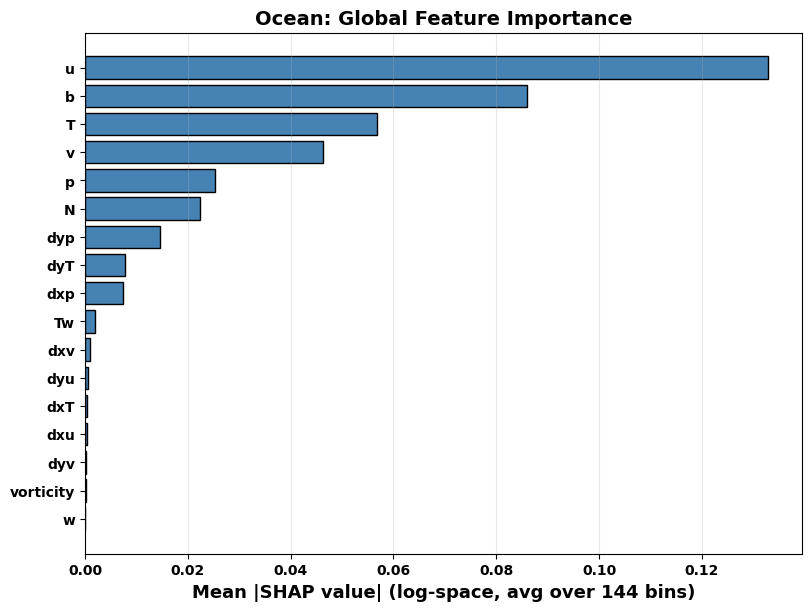

         u: 0.1328
         b: 0.0860
         T: 0.0569
         v: 0.0462
         p: 0.0253
         N: 0.0224
       dyp: 0.0145
       dyT: 0.0078
       dxp: 0.0073
        Tw: 0.0020
       dxv: 0.0010
       dyu: 0.0006
       dxT: 0.0004
       dxu: 0.0004
       dyv: 0.0003
 vorticity: 0.0003
         w: 0.0001


In [3]:
import numpy as np
import matplotlib.pyplot as plt

shap_dir = "/work/bb1097/b383521/ML_models/coarsed_grained/shap/"

sv_ocean = np.load(shap_dir + "svglobal_ocean.npy")  # shape (100, 102, 144)
sv_land  = np.load(shap_dir + "svglobal_land.npy")  # shape(100, 111, 144)

print("Shape:", sv_ocean.shape)  # (n_samples, n_features, n_output_bins)

keys = ["u", "v", "w", "p", "T", "N", "b", "Tw", "dxu", "dyu", "dxv",
        "dyv", "dxT", "dyT", "dxp", "dyp", "vorticity"]

n_keys = len(keys)  # 17

# --- Average |SHAP| over samples AND all 144 output bins ---
importance_full = np.mean(np.abs(sv_ocean), axis=(0, 2))  # shape (102,)

# --- Reshape into (n_keys, 6) to get per-variable importance ---
importance_by_level = importance_full.reshape(n_keys, 6)
importance_per_variable = importance_by_level.mean(axis=1)  # shape (17,)

# --- Sort and plot ---
order = np.argsort(importance_per_variable)[::-1]
sorted_names = [keys[i] for i in order]
sorted_importance = importance_per_variable[order]

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.barh(sorted_names[::-1], sorted_importance[::-1], color="steelblue", edgecolor="black")
ax.set_xlabel("Mean |SHAP value| (log-space, avg over 144 bins)", fontweight="bold", fontsize=13)
ax.set_title("Ocean: Global Feature Importance", fontweight="bold", fontsize=14)
ax.grid(axis="x", alpha=0.3)
for lbl in ax.get_yticklabels() + ax.get_xticklabels():
    lbl.set_fontweight("bold")

plt.show()

for name, val in zip(sorted_names, sorted_importance):
    print(f"{name:>10}: {val:.4f}")

In [5]:
A = sv_ocean.mean(axis=(0, 2))

In [8]:
A = A.reshape(17, 6)

In [17]:
keys = ["u", "v", "w", "p", "T", "N", "b", "Tw", "dxu", "dyu", "dxv",
        "dyv", "dxT", "dyT", "dxp", "dyp", "vorticity"]
A[8]

array([ 2.94513058e-05,  1.93621597e-04,  8.34313343e-05,  2.32402945e-06,
        2.99091526e-06, -1.88978184e-05])

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

shap_dir = "/work/bb1097/b383521/ML_models/coarsed_grained/shap/"

sv_ocean = np.load(shap_dir + "svglobal_ocean.npy")  # (100, 102, 144)
sv_land  = np.load(shap_dir + "svglobal_land.npy")   # (100, 111, 144)

keys = ["u", "v", "w", "p", "T", "N", "b", "Tw", "dxu", "dyu", "dxv",
        "dyv", "dxT", "dyT", "dxp", "dyp", "vorticity"]
n_keys = len(keys)  # 17
n_dynamic = n_keys * 6  # 102

# Land-only orography/mask feature names -- UPDATE these to match your actual 9 (or 10) features
orography_keys = [
    "H_var",        # 0: total orographic variance (roughness), H_sum
    "mean_k",       # 1: power-weighted mean zonal wavenumber
    "mean_l",       # 2: power-weighted mean meridional wavenumber (signed)
    "ridge_wlen_k", # 3: effective zonal wavelength (1/k, weighted)
    "ridge_wlen_l", # 4: effective meridional wavelength (1/|l|, weighted)
    "spec_width_k", # 5: zonal spectral width
    "spec_width_l", # 6: meridional spectral width
    "anisotropy",   # 7: zonal/meridional power ratio
    "orientation",  # 8: dominant ridge orientation angle
]# adjust names/order to match your actual feature construction

def compute_importance(sv, has_orography=False):
    importance_full = np.mean(np.abs(sv), axis=(0, 2))  # (n_features,)
    dynamic_part = importance_full[:n_dynamic]
    importance_by_level = dynamic_part.reshape(n_keys, 6)
    importance_per_variable = importance_by_level.sum(axis=1)  # (17,)

    result = {"per_variable": importance_per_variable, "by_level": importance_by_level}
    if has_orography:
        result["orography"] = importance_full[n_dynamic:]
    return result

ocean_imp = compute_importance(sv_ocean, has_orography=False)
land_imp  = compute_importance(sv_land, has_orography=True)

# --- Combine dynamical + orography for land into one full set of names/values for plotting ---
land_all_names = keys + orography_keys[:len(land_imp["orography"])]
land_all_values = np.concatenate([land_imp["per_variable"], land_imp["orography"]])

ocean_all_names = keys
ocean_all_values = ocean_imp["per_variable"]

def plot_sorted_bar(ax, names, values, title):
    order = np.argsort(values)[::-1]
    sorted_names = [names[i] for i in order]
    sorted_values = values[order]
    ax.barh(sorted_names[::-1], sorted_values[::-1], color="steelblue", edgecolor="black")
    ax.set_xlabel("Mean |SHAP value|", fontweight="bold", fontsize=12)
    ax.set_title(title, fontweight="bold", fontsize=13)
    ax.grid(axis="x", alpha=0.3)
    for lbl in ax.get_yticklabels() + ax.get_xticklabels():
        lbl.set_fontweight("bold")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
plot_sorted_bar(axes[0], ocean_all_names, ocean_all_values, "Ocean: Global Feature Importance")
plot_sorted_bar(axes[1], land_all_names, land_all_values, "Land: Global Feature Importance")

plt.savefig("shap_global_ocean_land.png", dpi=400, bbox_inches="tight")
plt.show()

groups = {
    "Dynamical (u, v)": ["u", "v"],
    "Thermodynamic (b, T, N)": ["b", "T", "N"],
    "Pressure (p)": ["p"],
    "Vertical motion (w)": ["w"],
    "Flux/other (Tw, vorticity)": ["Tw", "vorticity"],
    "Gradients": ["dxu","dyu","dxv","dyv","dxT","dyT","dxp","dyp"],
}

def compute_grouped_importance(importance_per_variable, keys, groups):
    grouped = {}
    for group_name, var_list in groups.items():
        idx = [keys.index(v) for v in var_list]
        grouped[group_name] = importance_per_variable[idx].sum()
    return grouped

ocean_grouped = compute_grouped_importance(ocean_imp["per_variable"], keys, groups)
land_grouped  = compute_grouped_importance(land_imp["per_variable"], keys, groups)

# Land also has orography as its own group
land_grouped["Orography (land only)"] = land_imp["orography"].sum()

print("=== OCEAN (grouped) ===")
for k, v in sorted(ocean_grouped.items(), key=lambda x: -x[1]):
    print(f"{k:<28}: {v:.4f}")

print("\n=== LAND (grouped) ===")
for k, v in sorted(land_grouped.items(), key=lambda x: -x[1]):
    print(f"{k:<28}: {v:.4f}")

=== OCEAN (grouped) ===
Dynamical (u, v)            : 1.0740
Thermodynamic (b, T, N)     : 0.9915
Gradients                   : 0.1942
Pressure (p)                : 0.1517
Flux/other (Tw, vorticity)  : 0.0138
Vertical motion (w)         : 0.0006

=== LAND (grouped) ===
Thermodynamic (b, T, N)     : 1.7742
Dynamical (u, v)            : 0.9836
Pressure (p)                : 0.3068
Gradients                   : 0.1211
Flux/other (Tw, vorticity)  : 0.0119
Orography (land only)       : 0.0038
Vertical motion (w)         : 0.0002


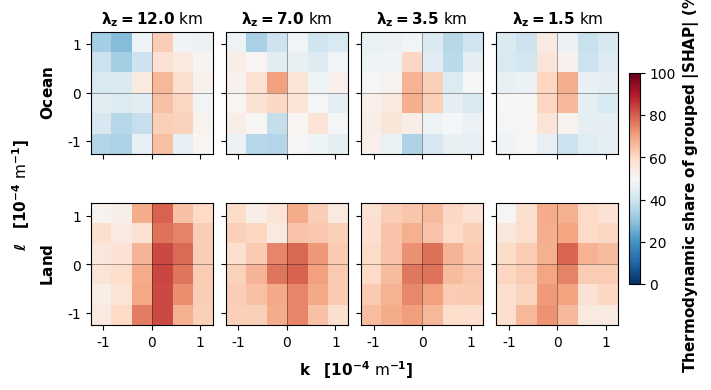

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np


def compute_group_spectral_map(sv, keys, group_vars, n_k=6, n_l=6, n_m=4):
    """Returns (6,6,4) map of summed |SHAP| for the given group,

    averaged over samples, summed over the group's variables and their 6 levels.
    """
    group_shap_sum = np.zeros((sv.shape[0], sv.shape[2]))  # (n_samples, 144)
    for var in group_vars:
        var_start = keys.index(var) * 6
        var_shap = sv[:, var_start : var_start + 6, :]  # (n_samples, 6, 144)
        group_shap_sum += np.sum(
            np.abs(var_shap), axis=1
        )  # sum over levels -> (n_samples, 144)
    group_shap_mean = np.mean(
        group_shap_sum, axis=0
    )  # avg over samples -> (144,)
    return group_shap_mean.reshape(n_k, n_l, n_m)


def compute_relative_attribution_map(sv, keys, group_a_vars, group_b_vars):
    """Returns (6,6,4) map of group_a's percentage share relative to (group_a +

    group_b), per spectral bin: 100 * I_a / (I_a + I_b)
    """
    map_a = compute_group_spectral_map(sv, keys, group_a_vars)
    map_b = compute_group_spectral_map(sv, keys, group_b_vars)
    pct_a = 100.0 * map_a / (map_a + map_b)
    return pct_a


def plot_relative_attribution_ocean_land(
    field_ocean,
    field_land,
    k,
    l,
    m,
    cbar_label,
    savename,
    cmap="RdBu_r",
    vmin=0,
    vmax=100,
    fontsize=11,
    n_ticks=3,
):
    field_ocean = np.nan_to_num(field_ocean, nan=0.0)
    field_land = np.nan_to_num(field_land, nan=0.0)

    extent = [k.min(), k.max(), l.min(), l.max()]
    nm = len(m)

    fig, axes = plt.subplots(
        2,
        nm,
        figsize=(7.0, 3.8),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if nm == 1:
        axes = axes.reshape(2, 1)

    for j in range(nm):
        lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
        fields = [field_ocean[:, :, j], field_land[:, :, j]]

        for i in range(2):
            ax = axes[i, j]

            im = ax.imshow(
                fields[i].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )

            ax.axhline(0, color="k", lw=0.6, alpha=0.4)
            ax.axvline(0, color="k", lw=0.6, alpha=0.4)

            # Subpanel headers (Bolded)
            if i == 0:
                ax.set_title(
                    rf"$\mathbf{{\lambda_z = {lambda_km:.1f}\text{{ km}}}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            # Row identity labels (Ocean / Land - Bolded)
            if j == 0:
                label_prefix = "Ocean" if i == 0 else "Land"
                ax.set_ylabel(
                    rf"$\mathbf{{{label_prefix}}}$",
                    fontsize=fontsize,
                    labelpad=8,
                )

            ax.xaxis.set_major_locator(mticker.MaxNLocator(n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(n_ticks))

            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

    # Single centered figure-level axis labels (Bolded)
    fig.supxlabel(
        r"$\mathbf{k \quad [10^{-4}\text{ m}^{-1}]}$", fontsize=fontsize
    )
    fig.supylabel(
        r"$\mathbf{\ell \quad [10^{-4}\text{ m}^{-1}]}$", fontsize=fontsize
    )

    # Colorbar (Bolded label)
    cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="bold")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Usage ---
pct_ocean = compute_relative_attribution_map(
    sv_ocean, keys, ["b", "T", "N"], ["u", "v"]
)
pct_land = compute_relative_attribution_map(
    sv_land, keys, ["b", "T", "N"], ["u", "v"]
)

plot_relative_attribution_ocean_land(
    field_ocean=pct_ocean,
    field_land=pct_land,
    k=k_wavenumber_array,
    l=l_wavenumber_array,
    m=m,
    cbar_label=r"$\mathbf{Thermodynamic\ share\ of\ grouped\ |SHAP|\ (\%)}$",
    savename="shap_relative_attribution_thermo",
    cmap="RdBu_r",
)

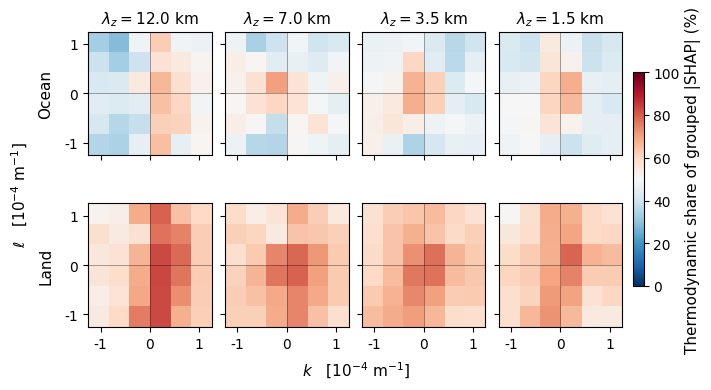

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def compute_group_spectral_map(sv, keys, group_vars, n_k=6, n_l=6, n_m=4):
    """
    Returns (6,6,4) map of summed |SHAP| for the given group,
    averaged over samples, summed over the group's variables and their 6 levels.
    """
    group_shap_sum = np.zeros((sv.shape[0], sv.shape[2]))  # (n_samples, 144)
    for var in group_vars:
        var_start = keys.index(var) * 6
        var_shap = sv[:, var_start:var_start+6, :]           # (n_samples, 6, 144)
        group_shap_sum += np.sum(np.abs(var_shap), axis=1)   # sum over levels -> (n_samples, 144)
    group_shap_mean = np.mean(group_shap_sum, axis=0)         # avg over samples -> (144,)
    return group_shap_mean.reshape(n_k, n_l, n_m)


def compute_relative_attribution_map(sv, keys, group_a_vars, group_b_vars):
    """
    Returns (6,6,4) map of group_a's percentage share relative to (group_a + group_b),
    per spectral bin: 100 * I_a / (I_a + I_b)
    """
    map_a = compute_group_spectral_map(sv, keys, group_a_vars)
    map_b = compute_group_spectral_map(sv, keys, group_b_vars)
    pct_a = 100.0 * map_a / (map_a + map_b)
    return pct_a


def plot_relative_attribution_ocean_land(
    field_ocean,
    field_land,
    k,
    l,
    m,
    cbar_label,
    savename,
    cmap="RdBu_r",
    vmin=0,
    vmax=100,
    fontsize=11,
    n_ticks=3,
):
    field_ocean = np.nan_to_num(field_ocean, nan=0.0)
    field_land = np.nan_to_num(field_land, nan=0.0)

    extent = [k.min(), k.max(), l.min(), l.max()]
    nm = len(m)

    fig, axes = plt.subplots(
        2,
        nm,
        figsize=(7.0, 3.8),
        sharex="col",
        sharey="row",
        constrained_layout=True,
    )

    if nm == 1:
        axes = axes.reshape(2, 1)

    for j in range(nm):
        lambda_km = 2 * np.pi / np.abs(m[j]) / 1000.0
        fields = [field_ocean[:, :, j], field_land[:, :, j]]

        for i in range(2):
            ax = axes[i, j]

            im = ax.imshow(
                fields[i].T,
                origin="lower",
                extent=extent,
                interpolation="nearest",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )

            ax.axhline(0, color="k", lw=0.6, alpha=0.4)
            ax.axvline(0, color="k", lw=0.6, alpha=0.4)

            if i == 0:
                ax.set_title(
                    rf"$\lambda_z = {lambda_km:.1f}\text{{ km}}$",
                    fontsize=fontsize,
                    pad=6,
                )

            if j == 0:
                label_prefix = "Ocean" if i == 0 else "Land"
                ax.set_ylabel(label_prefix, fontsize=fontsize, labelpad=8)

            ax.xaxis.set_major_locator(mticker.MaxNLocator(n_ticks))
            ax.yaxis.set_major_locator(mticker.MaxNLocator(n_ticks))

            ax.xaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, pos: f"{int(round(x*1e4))}")
            )
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda y, pos: f"{int(round(y*1e4))}")
            )

            ax.tick_params(labelsize=fontsize - 1)

    fig.supxlabel(r"$k \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)
    fig.supylabel(r"$\ell \quad [10^{-4}\text{ m}^{-1}]$", fontsize=fontsize)

    cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()


# --- Usage ---
pct_ocean = compute_relative_attribution_map(sv_ocean, keys, ["b", "T", "N"], ["u", "v"])
pct_land  = compute_relative_attribution_map(sv_land, keys, ["b", "T", "N"], ["u", "v"])

plot_relative_attribution_ocean_land(
    field_ocean=pct_ocean,
    field_land=pct_land,
    k=k_wavenumber_array,
    l=l_wavenumber_array,
    m=m,
    cbar_label="Thermodynamic share of grouped |SHAP| (%)",
    savename="shap_relative_attribution_thermo",
    cmap="RdBu_r",
)

In [ ]:
for i in range(4):
    print(f"land avarge of the thermodynmic at vertical wave length of {2*np.pi/m[i]/1000}km attribution {np.mean(pct_land[:, :, i])}")
    print(f"ocean avarge of the thermodynmic attribution at vertical wave length of {2*np.pi/m[i]/1000}km {np.mean(pct_ocean[:, :, i])}")
    

land avarge of the thermodynmic at vertical wave length of 12.000000000000002km attribution 65.91691675899365
ocean avarge of the thermodynmic attribution at vertical wave length of 12.000000000000002km 48.154515176303825
land avarge of the thermodynmic at vertical wave length of 7.0km attribution 65.0267966467851
ocean avarge of the thermodynmic attribution at vertical wave length of 7.0km 48.85806051663329
land avarge of the thermodynmic at vertical wave length of 3.5km attribution 65.13468798579773
ocean avarge of the thermodynmic attribution at vertical wave length of 3.5km 49.03239370375852
land avarge of the thermodynmic at vertical wave length of 1.5000000000000002km attribution 63.367495599800435
ocean avarge of the thermodynmic attribution at vertical wave length of 1.5000000000000002km 48.258232781236806


In [31]:
for i in range(4):

    lz_km = 2 * np.pi / m[i] / 1000

    # -----------------------------
    # Basic statistics
    # -----------------------------
    land = pct_land[:, :, i]
    ocean = pct_ocean[:, :, i]

    print("\n" + "="*70)
    print(f"Vertical wavelength: λz = {lz_km:.2f} km")
    print("="*70)

    print("\nLAND")
    print(f"  Mean        : {np.mean(land):.2f}%")
    print(f"  Median      : {np.median(land):.2f}%")
    print(f"  Std         : {np.std(land):.2f} percentage points")
    print(f"  Minimum     : {np.min(land):.2f}%")
    print(f"  Maximum     : {np.max(land):.2f}%")
    print(f"  Range       : {np.ptp(land):.2f} percentage points")
    print(f"  >50% bins   : {np.sum(land > 50)}/36 "
          f"({100*np.mean(land > 50):.1f}%)")

    print("\nOCEAN")
    print(f"  Mean        : {np.mean(ocean):.2f}%")
    print(f"  Median      : {np.median(ocean):.2f}%")
    print(f"  Std         : {np.std(ocean):.2f} percentage points")
    print(f"  Minimum     : {np.min(ocean):.2f}%")
    print(f"  Maximum     : {np.max(ocean):.2f}%")
    print(f"  Range       : {np.ptp(ocean):.2f} percentage points")
    print(f"  >50% bins   : {np.sum(ocean > 50)}/36 "
          f"({100*np.mean(ocean > 50):.1f}%)")

    # -----------------------------
    # Land-ocean difference
    # -----------------------------
    difference = land - ocean

    print("\nLAND − OCEAN")
    print(f"  Mean difference : {np.mean(difference):.2f} percentage points")
    print(f"  Minimum         : {np.min(difference):.2f} pp")
    print(f"  Maximum         : {np.max(difference):.2f} pp")
    print(f"  Std             : {np.std(difference):.2f} pp")


Vertical wavelength: λz = 12.00 km

LAND
  Mean        : 65.92%
  Median      : 62.51%
  Std         : 9.84 percentage points
  Minimum     : 51.92%
  Maximum     : 83.49%
  Range       : 31.57 percentage points
  >50% bins   : 36/36 (100.0%)

OCEAN
  Mean        : 48.15%
  Median      : 47.48%
  Std         : 10.16 percentage points
  Minimum     : 28.31%
  Maximum     : 66.62%
  Range       : 38.31 percentage points
  >50% bins   : 15/36 (41.7%)

LAND − OCEAN
  Mean difference : 17.76 percentage points
  Minimum         : 10.09 pp
  Maximum         : 30.89 pp
  Std             : 5.18 pp

Vertical wavelength: λz = 7.00 km

LAND
  Mean        : 65.03%
  Median      : 63.13%
  Std         : 6.66 percentage points
  Minimum     : 53.26%
  Maximum     : 79.63%
  Range       : 26.36 percentage points
  >50% bins   : 36/36 (100.0%)

OCEAN
  Mean        : 48.86%
  Median      : 48.78%
  Std         : 7.50 percentage points
  Minimum     : 33.91%
  Maximum     : 70.64%
  Range       : 36.74 

In [32]:
for i in range(4):

    lz_km = 2 * np.pi / m[i] / 1000

    land = pct_land[:, :, i]
    ocean = pct_ocean[:, :, i]

    # Land maximum/minimum
    land_max_idx = np.unravel_index(np.argmax(land), land.shape)
    land_min_idx = np.unravel_index(np.argmin(land), land.shape)

    # Ocean maximum/minimum
    ocean_max_idx = np.unravel_index(np.argmax(ocean), ocean.shape)
    ocean_min_idx = np.unravel_index(np.argmin(ocean), ocean.shape)

    print("\n" + "="*70)
    print(f"λz = {lz_km:.2f} km")
    print("="*70)

    print(
        f"LAND  max: {land[land_max_idx]:.2f}% "
        f"at k={k[land_max_idx[0]]:.2e}, "
        f"l={l[land_max_idx[1]]:.2e}"
    )

    print(
        f"LAND  min: {land[land_min_idx]:.2f}% "
        f"at k={k[land_min_idx[0]]:.2e}, "
        f"l={l[land_min_idx[1]]:.2e}"
    )

    print(
        f"OCEAN max: {ocean[ocean_max_idx]:.2f}% "
        f"at k={k[ocean_max_idx[0]]:.2e}, "
        f"l={l[ocean_max_idx[1]]:.2e}"
    )

    print(
        f"OCEAN min: {ocean[ocean_min_idx]:.2f}% "
        f"at k={k[ocean_min_idx[0]]:.2e}, "
        f"l={l[ocean_min_idx[1]]:.2e}"
    )


λz = 12.00 km


ValueError: Unknown format code 'e' for object of type 'str'